<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

## 0. Settings
Results from the files made in 06_band_power: band power (band_power_v3 = CMR, band_power_v3_localref = LOCAL; one file per session)
and bursts (bursts_karvat2021_v2; beta 15–30 and gamma 30–100, CMR and LOCAL, one representative channel per region).
Each result is first run on the test session (20260529_r0000136_wt_1318), then on all finished sessions.
Session = unit; sign-flip test across sessions (fn.sign_flip_p), per rat and all rats; raw p.

<div>

In [1]:
# %%
# ── 0. SETTINGS ──
import os, sys, glob, pickle, importlib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

MAIN      = r"C:\Users\ar687\Documents\GitHub\AmirAnalysis\main"
sys.path.insert(0, MAIN)
import functions as fn
importlib.reload(fn)

DATA_ROOT = r"O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data"
AMIR      = os.path.join(DATA_ROOT, "amir_data")
TABLES    = os.path.join(MAIN, "tables")
FIGS      = os.path.join(MAIN, "figures", "07_results")
BP_DIRS   = {"CMR":   os.path.join(DATA_ROOT, "analysis_main", "band_power_v3"),
             "LOCAL": os.path.join(DATA_ROOT, "analysis_main", "band_power_v3_localref")}
BURST_DIR = os.path.join(DATA_ROOT, "analysis_main", "bursts_karvat2021_v2")
os.makedirs(FIGS, exist_ok=True)
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 40)
warnings.filterwarnings("ignore", message="Mean of empty slice|All-NaN slice")

final = pd.read_csv(os.path.join(TABLES, "final_sessions.csv"), dtype={"rat": str})
RAT   = final.set_index("session")["rat"]
BANDS = list(fn.MAIN_BANDS)
TEST  = "20260529_r0000136_wt_1318"

def load_bp(session, ref="CMR"):
    """One band-power file (06_band_power) -> dict (meta, trials, logpow, curves, counts, times, spectra, spec_n)."""
    with open(os.path.join(BP_DIRS[ref], session + ".pkl"), "rb") as f:
        return pickle.load(f)

def done_sessions(ref="CMR"):
    """Final sessions whose band-power file exists (the run may still be going)."""
    return [s for s in final["session"] if os.path.exists(os.path.join(BP_DIRS[ref], s + ".pkl"))]

print("band power done:", {r: len(done_sessions(r)) for r in BP_DIRS}, "of", len(final))
print("bursts done:", sum(os.path.exists(os.path.join(BURST_DIR, s + ".npz")) for s in final["session"]), "of", len(final))
r = load_bp(TEST)
print(f"test file: {r['meta']['n_trials']} trials, {len(r['meta']['channel_ids'])} channels, windows {list(r['logpow'][BANDS[0]])}")

band power done: {'CMR': 1, 'LOCAL': 0} of 60
bursts done: 1 of 60
test file: 139 trials, 383 channels, windows ['pre', 'hold_early', 'hold', 'pre_release', 'post', 'pre_tone', 'post_tone']


<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

## 1. M1: does power change while the rat holds the lever? (correct long, CMR)
Per trial and channel: log10(power in the hold 0.20–0.85 s) − log10(power before the press −0.5..−0.2 s) ("hold-pre"),
and − log10(power after the release 0.2–0.5 s) ("hold-post"). Mean over correct long trials -> median over channels -> one value per session
(sessions with >= 10 correct long trials). Sign-flip test across sessions (10,000 flips), per rat and all rats; shown as % change; raw p.
All long_prob blocks (new filter). Earlier result (2026-10-20, old filter, 0.5 blocks): theta hold-pre +29 % (30/30 sessions),
hold-post +56 %; beta +14 % / +20 %; high gamma −6 % / −7 %.
1a = test session, 1b = all finished sessions.

<div>

<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

### 1a. M1 on the test session (20260529_r0000136_wt_1318, CMR)
fn.m1_session on one file: correct long trials (all blocks), per channel the mean over trials of log10(hold / pre) and log10(hold / post),
then the median over channels; printed as % change per band.
Check: theta hold vs pre must equal the 06_band_power test (+30.7 %).

<div>

In [ ]:
# ── 1a. M1, TEST SESSION ──
importlib.reload(fn)
MIN_CL = 10
m, n_cl = fn.m1_session(load_bp(TEST, "CMR"), BANDS, MIN_CL)
print(f"{TEST}: correct long trials {n_cl}")
for b in BANDS:
    print(f"  {b:13s} hold vs pre {100 * (10 ** m[b]['hold-pre'] - 1):+6.1f} % | hold vs post {100 * (10 ** m[b]['hold-post'] - 1):+6.1f} %")

20260529_r0000136_wt_1318: correct long trials 49
  delta 1-3     hold vs pre   +5.1 % | hold vs post  +22.9 %
  theta 4-7     hold vs pre  +30.7 % | hold vs post  +37.1 %
  alpha 8-12    hold vs pre  +18.5 % | hold vs post  +25.7 %
  beta 13-29    hold vs pre   +4.3 % | hold vs post  +11.9 %
  lowG 30-60    hold vs pre   +3.9 % | hold vs post   +8.9 %
  highG 61-100  hold vs pre   -3.7 % | hold vs post   +5.9 %


<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

### 1b. M1 on all finished sessions (CMR)
The same value for every finished session (>= 10 correct long trials) -> table M1 (one row per session × band).
Sign-flip test across sessions (fn.sign_flip_p, 10,000 flips): is the mean over sessions different from 0? Per rat and all rats, raw p.
Output: mean % change, sessions up, number of sessions, p.
Saved: tables\M1_session_values_CMR.csv, tables\M1_stats_CMR.csv. Rerun when the band-power run (06) has finished all sessions.

<div>

In [ ]:

# ─1b. M1, ALL FINISHED SESSIONS (sign-flip across sessions) ──
importlib.reload(fn)
REF = "CMR"
rows = []
for s in done_sessions(REF):
    m, n_cl = fn.m1_session(load_bp(s, REF), BANDS, MIN_CL)
    if m is None:
        continue
    for b in BANDS:
        rows.append({"session": s, "rat": RAT[s], "band": b, "n_cl": n_cl, **m[b]})
M1 = pd.DataFrame(rows)
M1.to_csv(os.path.join(TABLES, f"M1_session_values_{REF}.csv"), index=False)
print(f"sessions with >= {MIN_CL} correct long trials: {M1['session'].nunique()} of {len(done_sessions(REF))} finished")

stat = []
for meas in ["hold-pre", "hold-post"]:
    for b in BANDS:
        for rat in ["all"] + sorted(M1["rat"].unique()):
            v = M1[(M1["band"] == b) & ((M1["rat"] == rat) if rat != "all" else True)][meas]
            mean, p, n = fn.sign_flip_p(v.values)
            stat.append({"measure": meas, "band": b, "rat": rat, "n_sessions": n, "sessions_up": int((v > 0).sum()),
                         "mean_%": round(100 * (10 ** mean - 1), 1) if n else np.nan, "p": round(p, 4) if n >= 2 else np.nan})
M1_stat = pd.DataFrame(stat)
M1_stat.to_csv(os.path.join(TABLES, f"M1_stats_{REF}.csv"), index=False)
for meas, d in M1_stat.groupby("measure", sort=False):
    print(f"\n===== M1 {meas} ({REF}) =====")
    print(d.pivot(index="band", columns="rat", values=["mean_%", "sessions_up", "n_sessions", "p"]).loc[BANDS].to_string())

sessions with >= 10 correct long trials: 1 of 1 finished

===== M1 hold-pre (CMR) =====
             mean_%       sessions_up      n_sessions        p    
rat             136   all         136  all        136  all 136 all
band                                                              
delta 1-3       5.1   5.1         1.0  1.0        1.0  1.0 NaN NaN
theta 4-7      30.7  30.7         1.0  1.0        1.0  1.0 NaN NaN
alpha 8-12     18.5  18.5         1.0  1.0        1.0  1.0 NaN NaN
beta 13-29      4.3   4.3         1.0  1.0        1.0  1.0 NaN NaN
lowG 30-60      3.9   3.9         1.0  1.0        1.0  1.0 NaN NaN
highG 61-100   -3.7  -3.7         0.0  0.0        1.0  1.0 NaN NaN

===== M1 hold-post (CMR) =====
             mean_%       sessions_up      n_sessions        p    
rat             136   all         136  all        136  all 136 all
band                                                              
delta 1-3      22.9  22.9         1.0  1.0        1.0  1.0 NaN NaN
theta 4-7

<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

### 1c. M1 per channel in one session (pilot figure)
One session, 20 channels (fn.select_channels, same rule as the pilot), correct long trials, CMR.
Per trial: log10(hold / pre) and log10(hold / post) from the band-power file; sign-flip test across TRIALS (5000 flips), raw p.
* = p < 0.05 vs before the press AND vs after the release, same direction; · = p < 0.05 in that panel only.
Colour = % change (geometric mean over trials). Pilot result (2026-10-19, 136_0529): theta hold-specific in 12/20 channels.
Saved: figures\07_results\M1_channels_<session>_<ref>.png and data\amir_data.

<div>

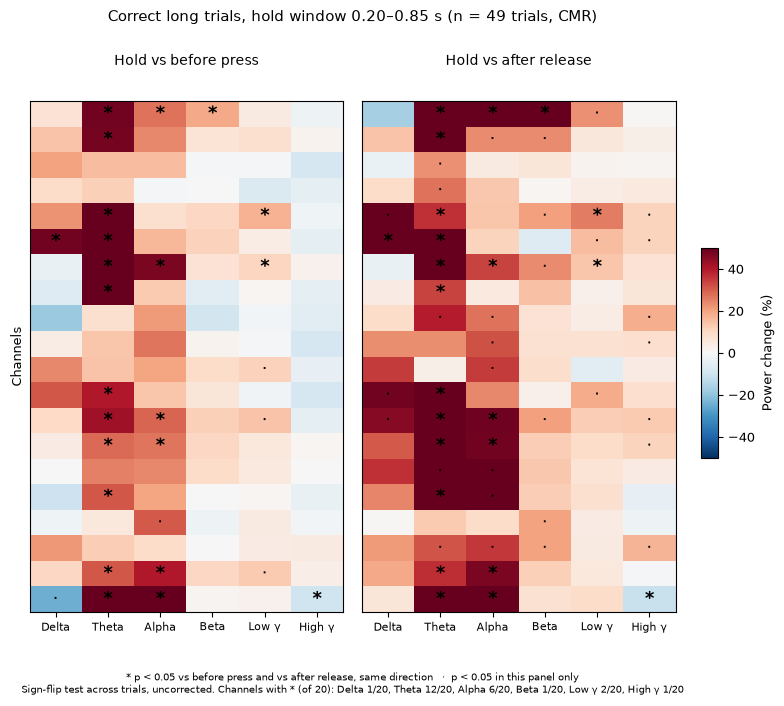

Delta 1/20, Theta 12/20, Alpha 6/20, Beta 1/20, Low γ 2/20, High γ 1/20


In [7]:
# %%
# ── 1c. M1 PER CHANNEL, ONE SESSION (pilot figure): sign-flip across trials ──
importlib.reload(fn)
SES_1D, REF_1D, NPERM_1D = TEST, "CMR", 5000
NAMES = {"delta 1-3": "Delta", "theta 4-7": "Theta", "alpha 8-12": "Alpha", "beta 13-29": "Beta",
         "lowG 30-60": "Low γ", "highG 61-100": "High γ"}

r = load_bp(SES_1D, REF_1D)
T, lp, meta = r["trials"], r["logpow"], r["meta"]
pdf = pd.DataFrame({"channel_id": meta["channel_ids"], "x": meta["x"], "y": meta["y"]})
pdf["shank"] = (pdf["x"] // 250).astype(int)
sel = fn.select_channels(pdf, n_total=20).sort_values(["shank", "y"], ascending=[True, False])
ci = [meta["channel_ids"].index(c) for c in sel["channel_id"]]
cl = ((T["label"] == "correct") & (T["type"] == "long")).values
n_tr = int(cl.sum())

pct = {k: np.full((len(ci), len(BANDS)), np.nan) for k in ("pre", "post")}
pv  = {k: np.full((len(ci), len(BANDS)), np.nan) for k in ("pre", "post")}
for j, b in enumerate(BANDS):
    for k in ("pre", "post"):
        R = lp[b]["hold"][cl][:, ci] - lp[b][k][cl][:, ci]                  # (trials, channels) log10 ratios
        for i in range(len(ci)):
            m, p, _ = fn.sign_flip_p(R[:, i], n_perm=NPERM_1D)
            pct[k][i, j], pv[k][i, j] = 100 * (10 ** m - 1), p
spec = (pv["pre"] < 0.05) & (pv["post"] < 0.05) & (np.sign(pct["pre"]) == np.sign(pct["post"]))
counts = ", ".join(f"{NAMES[b]} {int(spec[:, j].sum())}/{len(ci)}" for j, b in enumerate(BANDS))

plt.rcParams.update({"font.size": 9, "axes.linewidth": 0.8})
fig, axes = plt.subplots(1, 2, figsize=(8.5, 7), sharey=True)
for ax, k, ttl in zip(axes, ("pre", "post"), ("Hold vs before press", "Hold vs after release")):
    im = ax.imshow(pct[k], cmap="RdBu_r", vmin=-50, vmax=50, aspect="auto")
    for i in range(len(ci)):
        for j in range(len(BANDS)):
            if spec[i, j]:
                ax.text(j, i, "*", ha="center", va="center", fontsize=13, fontweight="bold")
            elif pv[k][i, j] < 0.05:
                ax.text(j, i, "·", ha="center", va="center", fontsize=13)
    ax.set_xticks(range(len(BANDS))); ax.set_xticklabels([NAMES[b] for b in BANDS], fontsize=8)
    ax.set_title(ttl, fontsize=10, pad=26)
axes[0].set_yticks([]); axes[0].set_ylabel("Channels")
fig.suptitle(f"Correct long trials, hold window 0.20–0.85 s (n = {n_tr} trials, {REF_1D})", fontsize=10.5, y=0.99)
fig.text(0.5, 0.01, "* p < 0.05 vs before press and vs after release, same direction   ·  p < 0.05 in this panel only\n"
         f"Sign-flip test across trials, uncorrected. Channels with * (of {len(ci)}): " + counts,
         ha="center", va="bottom", fontsize=7)
fig.subplots_adjust(bottom=0.13, top=0.86, left=0.12, right=0.88, wspace=0.06)
cb = fig.colorbar(im, cax=fig.add_axes([0.91, 0.35, 0.02, 0.3])); cb.set_label("Power change (%)")
for folder in (FIGS, AMIR):
    fig.savefig(os.path.join(folder, f"M1_channels_{SES_1D}_{REF_1D}.png"), dpi=300, facecolor="white", bbox_inches="tight")
plt.show()
print(counts)

<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

### 1d. M1 which bands change while the rat holds the lever? (correct long)
One dot = one session (colour = rat), black bar = mean over sessions; above each band: mean % change, sessions up / all, sign-flip P (raw).
Left: hold vs before the press; right: hold vs after the release. From table M1 (1b).
Saved: figures\07_results\M1_bands_hold_<ref>.png and data\amir_data\M1_bands_hold_<ref>.png (white background).

<div>

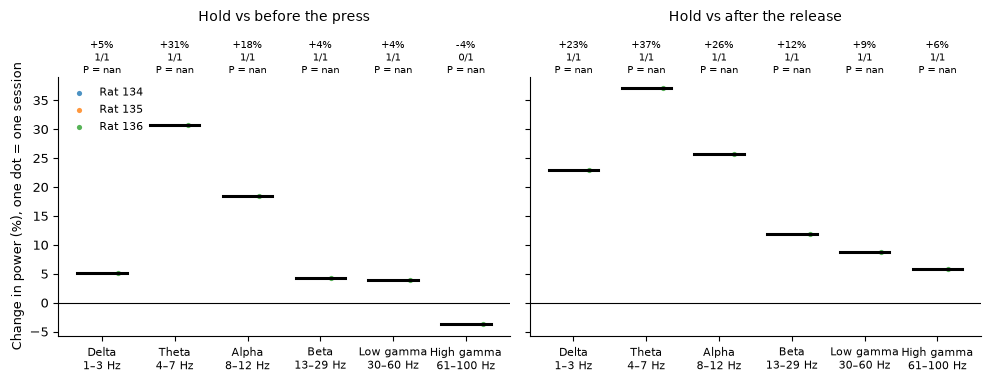

  measure         band  sessions  sessions_up  mean_pct   p
 hold-pre    delta 1-3         1            1    5.0619 NaN
 hold-pre    theta 4-7         1            1   30.7456 NaN
 hold-pre   alpha 8-12         1            1   18.4817 NaN
 hold-pre   beta 13-29         1            1    4.2670 NaN
 hold-pre   lowG 30-60         1            1    3.9309 NaN
 hold-pre highG 61-100         1            0   -3.7126 NaN
hold-post    delta 1-3         1            1   22.9143 NaN
hold-post    theta 4-7         1            1   37.0702 NaN
hold-post   alpha 8-12         1            1   25.6962 NaN
hold-post   beta 13-29         1            1   11.9151 NaN
hold-post   lowG 30-60         1            1    8.8537 NaN
hold-post highG 61-100         1            1    5.8570 NaN


In [6]:
# %%
# ── 1d. M1 SLIDE: one dot = one session, per band (needs 1b: M1, REF) ──
LAB = {"delta 1-3": "Delta\n1–3 Hz", "theta 4-7": "Theta\n4–7 Hz", "alpha 8-12": "Alpha\n8–12 Hz",
       "beta 13-29": "Beta\n13–29 Hz", "lowG 30-60": "Low gamma\n30–60 Hz", "highG 61-100": "High gamma\n61–100 Hz"}
RCOL = {"134": "#1f77b4", "135": "#ff7f0e", "136": "#2ca02c"}
PAN  = [("hold-pre", "Hold vs before the press"), ("hold-post", "Hold vs after the release")]

plt.rcParams.update({"font.size": 9, "axes.linewidth": 0.8})
fig, axes = plt.subplots(1, 2, figsize=(10, 3.9), sharey=True)
rng = np.random.default_rng(0); out = []
for ax, (col, title) in zip(axes, PAN):
    for i, b in enumerate(BANDS):
        d = M1[M1["band"] == b].dropna(subset=[col])
        for k, rat in enumerate(sorted(RCOL)):
            dr = d[d["rat"] == rat]
            ax.scatter(i + (k - 1) * 0.2 + rng.uniform(-0.05, 0.05, len(dr)), 100 * (10 ** dr[col] - 1), s=14,
                       color=RCOL[rat], alpha=0.8, linewidths=0, label=f"Rat {rat}" if (i == 0 and col == "hold-pre") else None)
        m, p, n = fn.sign_flip_p(d[col].values)
        ax.plot([i - 0.34, i + 0.34], [100 * (10 ** m - 1)] * 2, color="k", lw=2.2, zorder=4)
        ps = "P < 0.0001" if p < 1e-4 else f"P = {p:.3f}" if p >= 0.001 else f"P = {p:.4f}"
        ax.text(i, 1.0, f"{100 * (10 ** m - 1):+.0f}%\n{int((d[col] > 0).sum())}/{n}\n{ps}",
                transform=ax.get_xaxis_transform(), ha="center", va="bottom", fontsize=7.5)
        out.append(dict(measure=col, band=b, sessions=n, sessions_up=int((d[col] > 0).sum()), mean_pct=100 * (10 ** m - 1), p=p))
    ax.axhline(0, color="k", lw=0.8)
    ax.set_xticks(range(len(BANDS))); ax.set_xticklabels([LAB.get(b, b) for b in BANDS], fontsize=8)
    ax.set_title(title, fontsize=10, pad=40); ax.set_xlim(-0.6, len(BANDS) - 0.4)
    for sp in ("top", "right"): ax.spines[sp].set_visible(False)
axes[0].set_ylabel("Change in power (%), one dot = one session")
axes[0].legend(frameon=False, fontsize=8, loc="upper left")
fig.tight_layout()
pd.DataFrame(out).to_csv(os.path.join(TABLES, f"M1_bands_slide_values_{REF}.csv"), index=False)
for folder in (FIGS, AMIR):
    fig.savefig(os.path.join(folder, f"M1_bands_hold_{REF}.png"), dpi=300, facecolor="white", bbox_inches="tight")
plt.show()
print(pd.DataFrame(out).round(4).to_string(index=False))

<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

## 2. M2: correct long vs early long (CMR)
Is power different before an EARLY release than in a correct long trial? Windows relative to each trial's own pre-press (−0.5..−0.2 s):
pre_release (last 0.3 s before the release) and hold_early (0.10–0.30 s after the press).
Per channel: mean over correct long trials of log10(window / pre) minus the same for early long trials (hold > 0.3 s);
median over channels -> one value per session (>= 10 correct long and >= 5 early long trials). Positive = correct long higher.
Sign-flip test across sessions, per rat and all rats, raw p. All long_prob blocks.
Earlier result (2026-10-20, old filter, 0.5 blocks): nothing in hold_early; pre_release only high gamma correct > early (+5.3 %, mainly rat 135);
beta −3.2 % n.s.

<div>

<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

### 2a. M2 on the test session (CMR)
fn.m2_session on one file; trial counts per group and the correct − early difference per band and window (% change).

<div>

In [9]:
# %%
# ── 2a. M2, TEST SESSION ──
importlib.reload(fn)
MIN_EL, EARLY_MIN_HOLD = 5, 0.3
m, n_cl, n_el = fn.m2_session(load_bp(TEST, "CMR"), BANDS, MIN_CL, MIN_EL, EARLY_MIN_HOLD)
print(f"{TEST}: correct long {n_cl} | early long (hold > {EARLY_MIN_HOLD} s) {n_el}")
if m is None:
    print("too few trials for M2 in this session")
else:
    for b in BANDS:
        print(f"  {b:13s} pre_release correct − early {100 * (10 ** m[b]['pre_release'] - 1):+6.1f} % | "
              f"hold_early {100 * (10 ** m[b]['hold_early'] - 1):+6.1f} %")

20260529_r0000136_wt_1318: correct long 49 | early long (hold > 0.3 s) 13
  delta 1-3     pre_release correct − early  +22.6 % | hold_early   +8.2 %
  theta 4-7     pre_release correct − early   -3.9 % | hold_early   -0.3 %
  alpha 8-12    pre_release correct − early   -7.1 % | hold_early   -1.0 %
  beta 13-29    pre_release correct − early   +0.1 % | hold_early  -11.1 %
  lowG 30-60    pre_release correct − early   +1.4 % | hold_early   -4.2 %
  highG 61-100  pre_release correct − early   +1.1 % | hold_early   -8.9 %


<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

### 2b. M2 on all finished sessions (CMR)
The same value for every finished session -> table M2; sign-flip test across sessions per rat and all rats.
Saved: tables\M2_session_values_CMR.csv, tables\M2_stats_CMR.csv. Rerun when the band-power run (06) has finished.

<div>

In [10]:
# %%
# ── 2b. M2, ALL FINISHED SESSIONS ──
importlib.reload(fn)
rows = []
for s in done_sessions(REF):
    m, n_cl, n_el = fn.m2_session(load_bp(s, REF), BANDS, MIN_CL, MIN_EL, EARLY_MIN_HOLD)
    if m is None:
        continue
    for b in BANDS:
        rows.append({"session": s, "rat": RAT[s], "band": b, "n_cl": n_cl, "n_el": n_el, **m[b]})
M2 = pd.DataFrame(rows)
M2.to_csv(os.path.join(TABLES, f"M2_session_values_{REF}.csv"), index=False)
print(f"sessions with >= {MIN_CL} correct long and >= {MIN_EL} early long trials: "
      f"{M2['session'].nunique() if len(M2) else 0} of {len(done_sessions(REF))} finished")

stat = []
for w in ["pre_release", "hold_early"]:
    for b in BANDS:
        for rat in ["all"] + sorted(M2["rat"].unique() if len(M2) else []):
            v = M2[(M2["band"] == b) & ((M2["rat"] == rat) if rat != "all" else True)][w] if len(M2) else pd.Series(dtype=float)
            mean, p, n = fn.sign_flip_p(v.values)
            stat.append({"window": w, "band": b, "rat": rat, "n_sessions": n, "sessions_correct_higher": int((v > 0).sum()),
                         "mean_%": round(100 * (10 ** mean - 1), 1) if n else np.nan, "p": round(p, 4) if n >= 2 else np.nan})
M2_stat = pd.DataFrame(stat)
M2_stat.to_csv(os.path.join(TABLES, f"M2_stats_{REF}.csv"), index=False)
for w, d in M2_stat.groupby("window", sort=False):
    print(f"\n===== M2 {w}: correct long − early long ({REF}) =====")
    print(d.pivot(index="band", columns="rat", values=["mean_%", "sessions_correct_higher", "n_sessions", "p"]).loc[BANDS].to_string())

sessions with >= 10 correct long and >= 5 early long trials: 1 of 1 finished

===== M2 pre_release: correct long − early long (CMR) =====
             mean_%       sessions_correct_higher      n_sessions        p    
rat             136   all                     136  all        136  all 136 all
band                                                                          
delta 1-3      22.6  22.6                     1.0  1.0        1.0  1.0 NaN NaN
theta 4-7      -3.9  -3.9                     0.0  0.0        1.0  1.0 NaN NaN
alpha 8-12     -7.1  -7.1                     0.0  0.0        1.0  1.0 NaN NaN
beta 13-29      0.1   0.1                     1.0  1.0        1.0  1.0 NaN NaN
lowG 30-60      1.4   1.4                     1.0  1.0        1.0  1.0 NaN NaN
highG 61-100    1.1   1.1                     1.0  1.0        1.0  1.0 NaN NaN

===== M2 hold_early: correct long − early long (CMR) =====
             mean_%       sessions_correct_higher      n_sessions        p    
rat         

<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

## 3. Time courses: band power while holding (CMR)
Per trial: log10(power(t) / own pre-press power −0.5..−0.2 s), each trial only while the paw is on the lever; mean over the trials
of a condition (saved in the band-power files). Per session: median over all channels (>= 5 trials in the condition; time points
with < 3 trials still holding left out). Across sessions: median (shading = IQR across sessions), shown as % change.
Conditions: correct long, late short, correct short, early long (hold > 0.3 s). All long_prob blocks.
Press-aligned −0.7..2.0 s (dotted: tone short 0.35 s, long 1.05 s; grey: baseline window), release-aligned −1.5..0.6 s.
Earlier result (2026-10-20): theta (and beta) rise after the press in all holding conditions incl. early long, peak ~0.4–0.8 s,
drop at the release; high gamma −10 % during the hold.

<div>

<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

### 3a. Time courses in the test session
The four conditions in one session, median over all channels (shading = IQR across channels). Theta 4–7 and beta 13–29, Press and Release.
Compare with the pilot (2026-10-19, 5c): theta in correct long peaks ~+45 % at ~0.47 s.

<div>

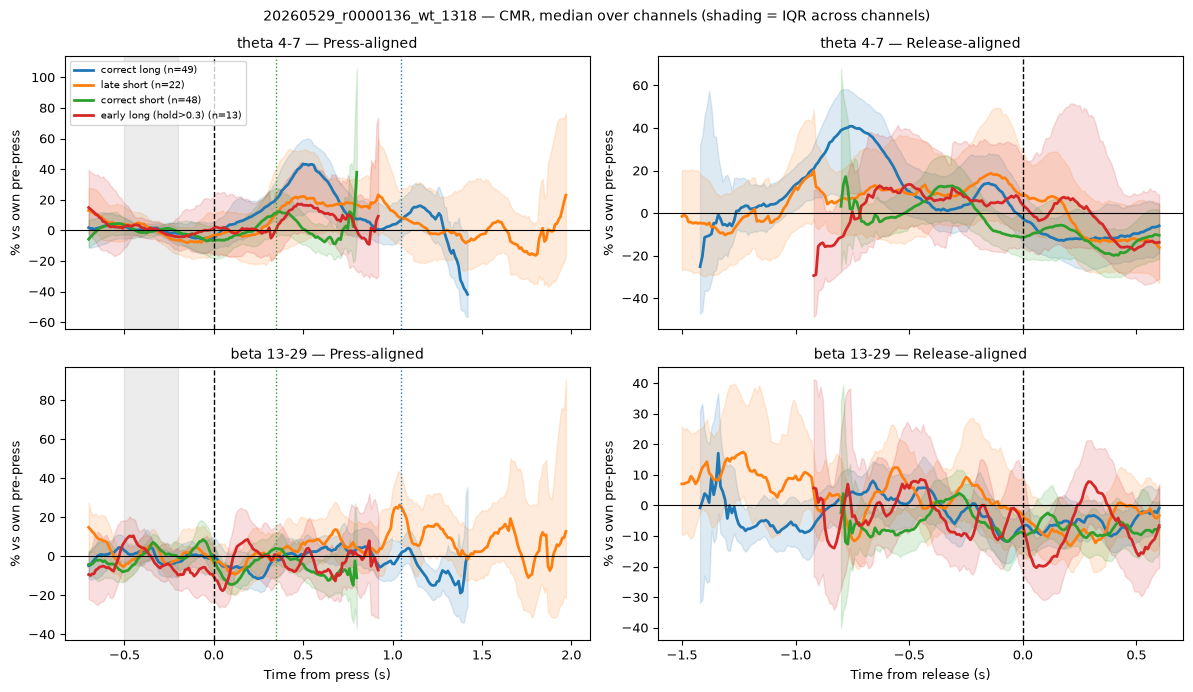

theta correct long, Press-aligned: peak +43 %


In [12]:
# %%
# ── 3a. TIME COURSES, TEST SESSION ──
importlib.reload(fn)
FIG_CONDS = {"correct long": "tab:blue", "late short": "tab:orange", "correct short": "tab:green", "early long (hold>0.3)": "tab:red"}
MIN_COND_TRIALS, MIN_ON = 5, 3
r = load_bp(TEST, "CMR")
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex="col")
for i, b in enumerate(["theta 4-7", "beta 13-29"]):
    for j, al in enumerate(["Press", "Release"]):
        ax, t = axes[i, j], r["times"][al]
        for c, col in FIG_CONDS.items():
            if fn.main_conditions(r["trials"])[c].sum() < MIN_COND_TRIALS:
                continue
            M = r["curves"][al][b][c]                                            # (channels, times)
            ok = r["counts"][al][c] >= MIN_ON
            med = 100 * (10 ** np.nanmedian(M, 0) - 1)
            q1, q3 = 100 * (10 ** np.nanpercentile(M, 25, 0) - 1), 100 * (10 ** np.nanpercentile(M, 75, 0) - 1)
            ax.plot(t[ok], med[ok], color=col, lw=2, label=f"{c} (n={int(fn.main_conditions(r['trials'])[c].sum())})")
            ax.fill_between(t[ok], q1[ok], q3[ok], color=col, alpha=0.15)
        ax.axhline(0, color="k", lw=0.8); ax.axvline(0, color="k", ls="--", lw=1)
        if al == "Press":
            ax.axvspan(*fn.MAIN_PRE, color="grey", alpha=0.15)
            ax.axvline(0.35, color="tab:green", ls=":", lw=1); ax.axvline(1.05, color="tab:blue", ls=":", lw=1)
        ax.set_title(f"{b} — {al}-aligned", fontsize=10); ax.set_ylabel("% vs own pre-press")
        if i == 1: ax.set_xlabel(f"Time from {al.lower()} (s)")
axes[0, 0].legend(fontsize=7, loc="upper left")
fig.suptitle(f"{TEST} — CMR, median over channels (shading = IQR across channels)", fontsize=10)
fig.tight_layout(); plt.show()
peak = np.nanmax(100 * (10 ** np.nanmedian(r["curves"]["Press"]["theta 4-7"]["correct long"], 0) - 1))
print(f"theta correct long, Press-aligned: peak {peak:+.0f} %")

<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

### 3b. Time courses across all finished sessions
All six bands (rows) × Press / Release (columns); one figure per rat and one for all rats; median across sessions
(each session = median over all channels; a condition is drawn only if >= 3 sessions have it).
Saved: figures\07_results\timecourse_<rat>_<ref>.png. Rerun when the band-power run (06) has finished.

<div>

sessions loaded: 1


C:\Users\ar687\AppData\Local\Temp\ipykernel_13024\304700041.py:29: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  if i == 0 and j == 0: ax.legend(fontsize=7, loc="upper left")


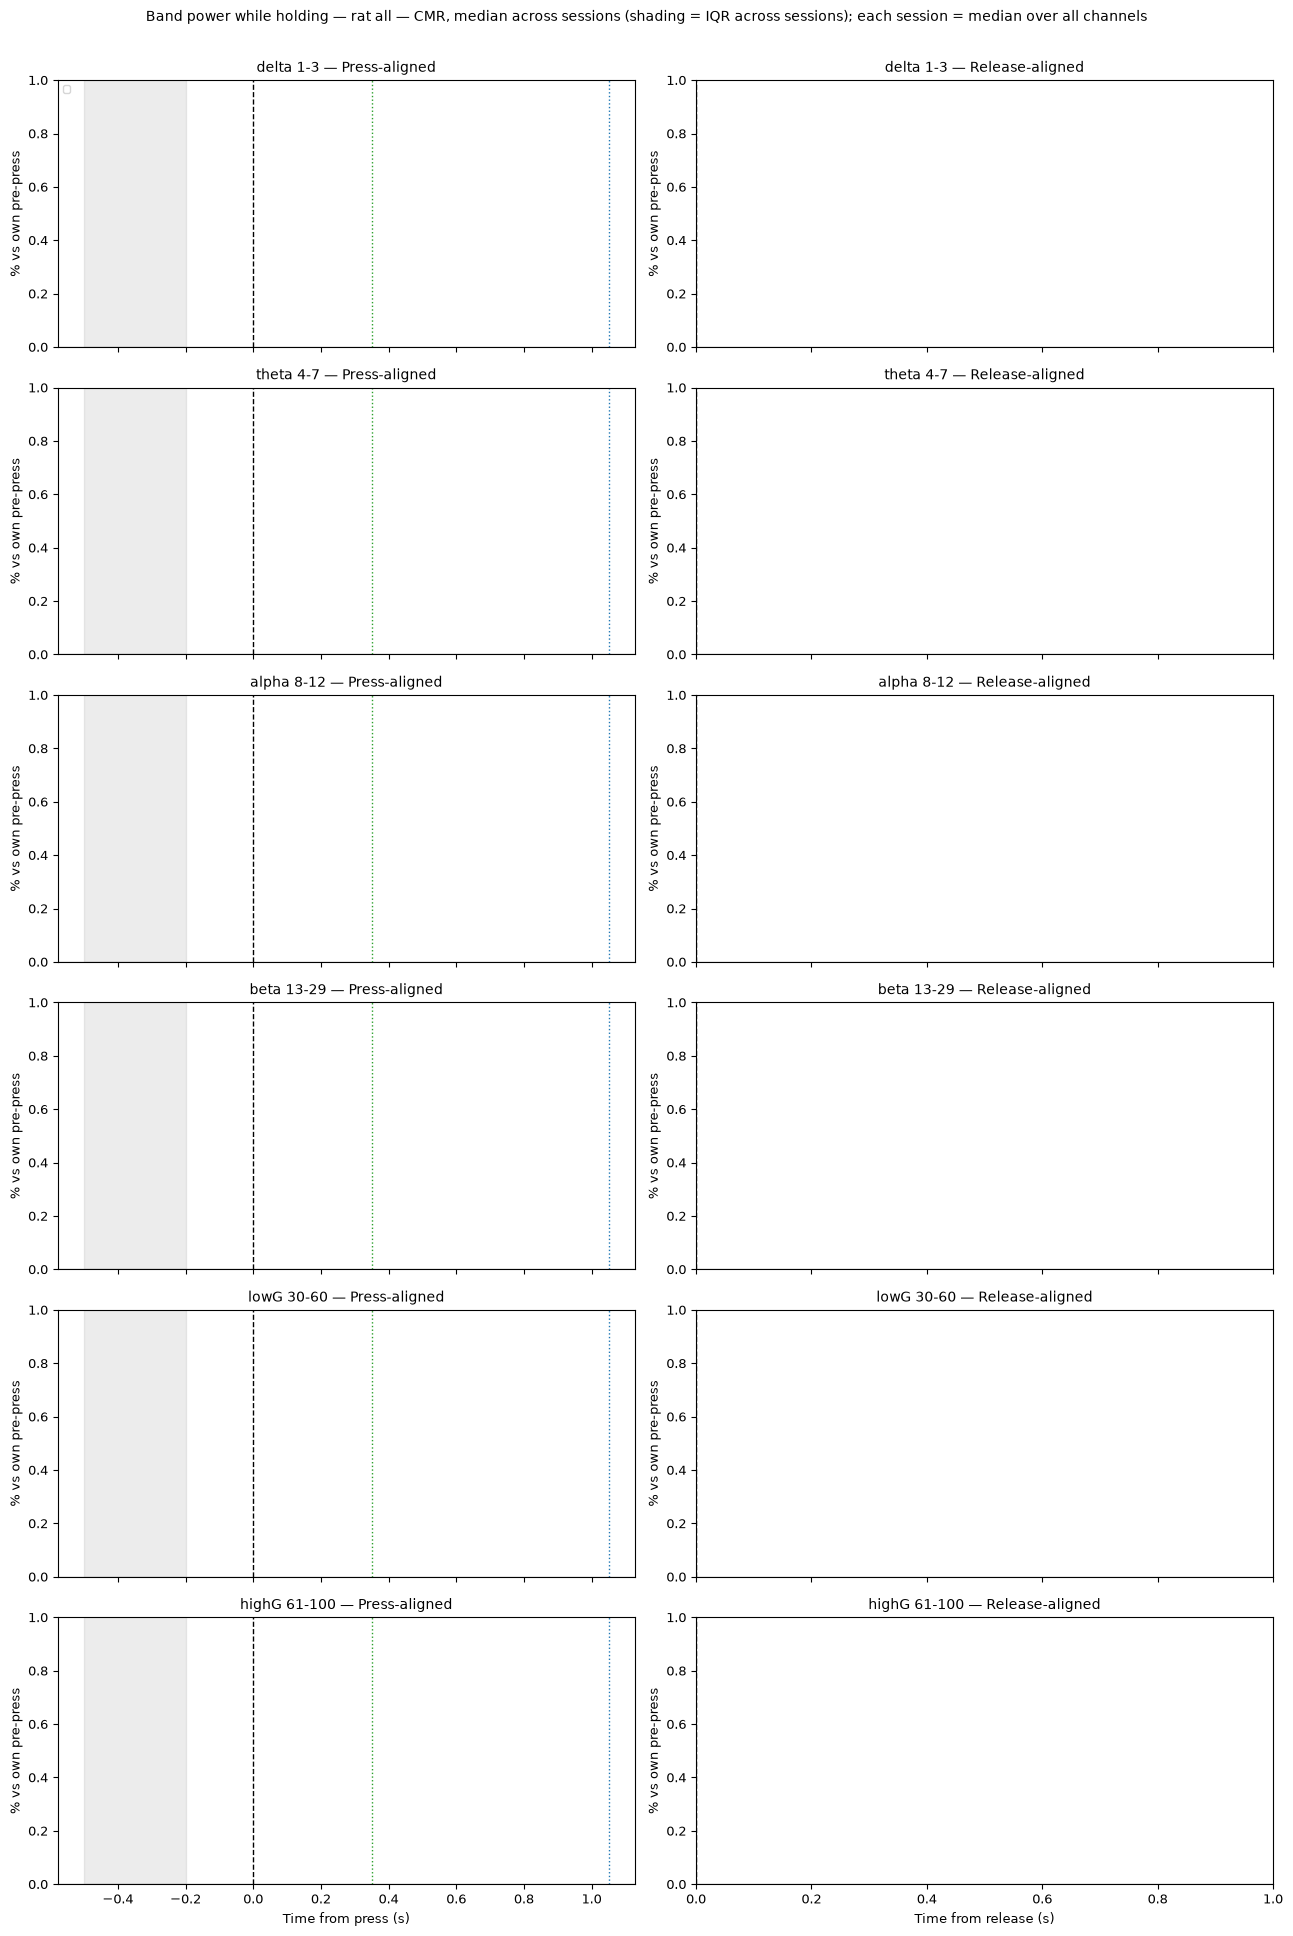

C:\Users\ar687\AppData\Local\Temp\ipykernel_13024\304700041.py:29: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  if i == 0 and j == 0: ax.legend(fontsize=7, loc="upper left")


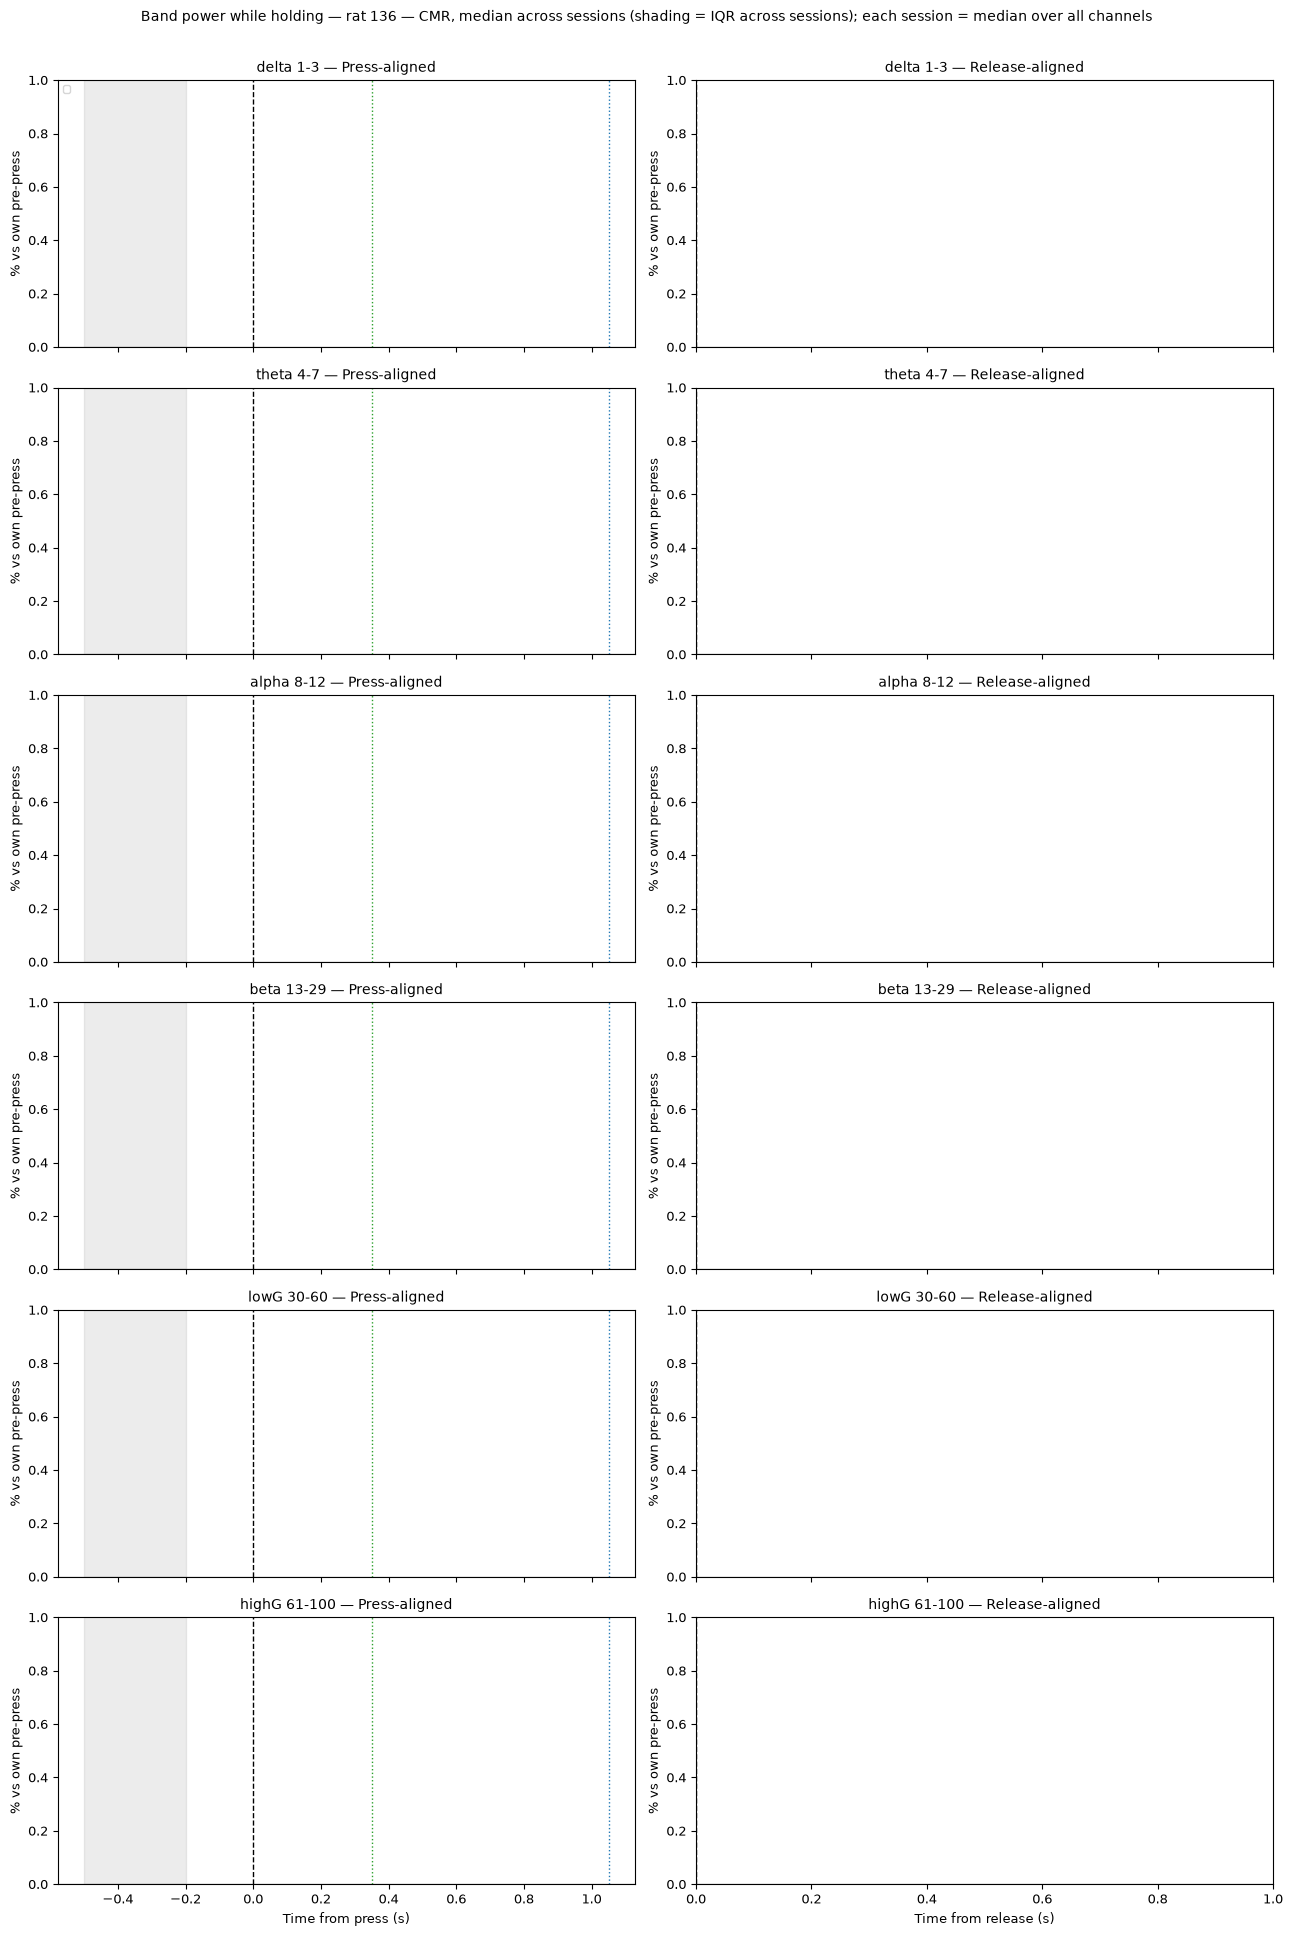

In [13]:
# %%
# ── 3b. TIME COURSES, ALL FINISHED SESSIONS (median across sessions) ──
importlib.reload(fn)
BP = {s: load_bp(s, REF) for s in done_sessions(REF)}
print(f"sessions loaded: {len(BP)}")
for rat in ["all"] + sorted({RAT[s] for s in BP}):
    ss = [s for s in BP if rat == "all" or RAT[s] == rat]
    fig, axes = plt.subplots(len(BANDS), 2, figsize=(13, 3.2 * len(BANDS)), sharex="col")
    for i, b in enumerate(BANDS):
        for j, al in enumerate(["Press", "Release"]):
            ax, t = axes[i, j], BP[ss[0]]["times"][al]
            for c, col in FIG_CONDS.items():
                M = [x for x in (fn.session_curve(BP[s], al, b, c, MIN_COND_TRIALS, MIN_ON) for s in ss) if x is not None]
                if len(M) < 3:
                    continue
                M = np.array(M); n_ok = np.isfinite(M).sum(0)
                with warnings.catch_warnings():
                    warnings.simplefilter("ignore", RuntimeWarning)
                    med = 100 * (10 ** np.nanmedian(M, 0) - 1)
                    q1, q3 = 100 * (10 ** np.nanpercentile(M, 25, 0) - 1), 100 * (10 ** np.nanpercentile(M, 75, 0) - 1)
                show = n_ok >= 3
                ax.plot(t[show], med[show], color=col, lw=2, label=f"{c} ({len(M)} sessions)")
                ax.fill_between(t[show], q1[show], q3[show], color=col, alpha=0.15)
            ax.axhline(0, color="k", lw=0.8); ax.axvline(0, color="k", ls="--", lw=1)
            if al == "Press":
                ax.axvspan(*fn.MAIN_PRE, color="grey", alpha=0.15)
                ax.axvline(0.35, color="tab:green", ls=":", lw=1); ax.axvline(1.05, color="tab:blue", ls=":", lw=1)
            ax.set_title(f"{b} — {al}-aligned", fontsize=10); ax.set_ylabel("% vs own pre-press")
            if i == 0 and j == 0: ax.legend(fontsize=7, loc="upper left")
            if i == len(BANDS) - 1: ax.set_xlabel(f"Time from {al.lower()} (s)")
    fig.suptitle(f"Band power while holding — rat {rat} — {REF}, median across sessions (shading = IQR across sessions); "
                 f"each session = median over all channels", fontsize=10, y=1.005)
    fig.tight_layout()
    fig.savefig(os.path.join(FIGS, f"timecourse_{rat}_{REF}.png"), dpi=150, facecolor="white", bbox_inches="tight")
    plt.show()

<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

### 3c. Pilot-style theta figure for one session
As pilot cell 5c: theta 4–7 Hz, CMR, median of the 20 selected channels (fn.select_channels), shading = IQR across channels,
curve hidden when < 8 trials are still holding. Made from the saved band-power curves (no recomputation).
Saved: figures\07_results\theta_timecourse_<session>_<ref>.png and data\amir_data.

<div>

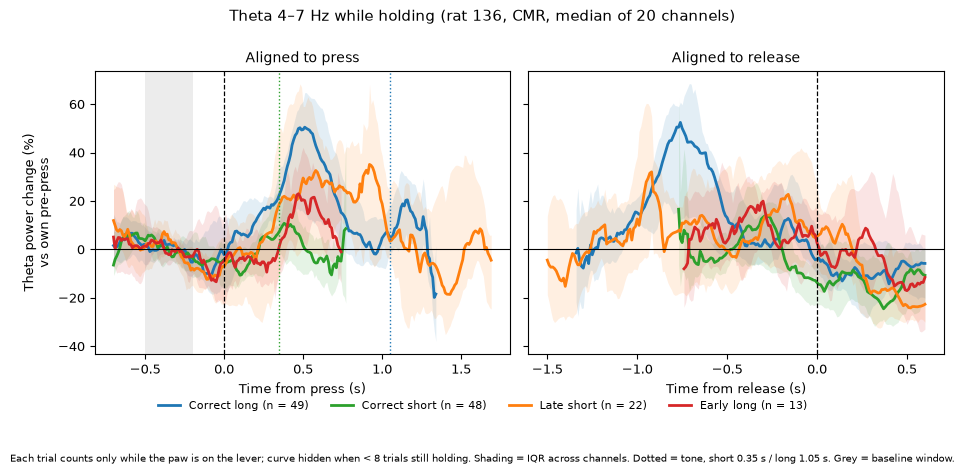

In [14]:
# %%
# ── 3c. PILOT-STYLE THETA FIGURE, ONE SESSION (20 selected channels) ──
importlib.reload(fn)
SES_3C, REF_3C, BAND_3C, MIN_TR = TEST, "CMR", "theta 4-7", 8
COL  = {"correct long": "tab:blue", "correct short": "tab:green", "late short": "tab:orange", "early long (hold>0.3)": "tab:red"}
NAME = {"correct long": "Correct long", "correct short": "Correct short", "late short": "Late short", "early long (hold>0.3)": "Early long"}

r = load_bp(SES_3C, REF_3C); meta = r["meta"]
pdf = pd.DataFrame({"channel_id": meta["channel_ids"], "x": meta["x"], "y": meta["y"]}); pdf["shank"] = (pdf["x"] // 250).astype(int)
sel = fn.select_channels(pdf, n_total=20)
ci = [meta["channel_ids"].index(c) for c in sel["channel_id"]]
conds = fn.main_conditions(r["trials"])

plt.rcParams.update({"font.size": 9, "axes.linewidth": 0.8})
fig, axes = plt.subplots(1, 2, figsize=(9.5, 4), sharey=True)
for ax, al in zip(axes, ["Press", "Release"]):
    t = r["times"][al]
    for c in COL:
        M = r["curves"][al][BAND_3C][c][ci]                                  # (20 channels, times)
        with np.errstate(invalid="ignore"), warnings.catch_warnings():
            warnings.simplefilter("ignore", RuntimeWarning)
            med = 100 * (10 ** np.nanmedian(M, 0) - 1)
            q1, q3 = 100 * (10 ** np.nanpercentile(M, 25, 0) - 1), 100 * (10 ** np.nanpercentile(M, 75, 0) - 1)
        s = r["counts"][al][c] >= MIN_TR
        ax.plot(t[s], med[s], color=COL[c], lw=2, label=f"{NAME[c]} (n = {int(conds[c].sum())})")
        ax.fill_between(t[s], q1[s], q3[s], color=COL[c], alpha=0.12, lw=0)
    ax.axhline(0, color="k", lw=0.8); ax.axvline(0, color="k", ls="--", lw=0.9)
    if al == "Press":
        ax.axvspan(*fn.MAIN_PRE, color="grey", alpha=0.15, lw=0)
        ax.axvline(0.35, color="tab:green", ls=":", lw=1); ax.axvline(1.05, color="tab:blue", ls=":", lw=1)
    ax.set_xlabel(f"Time from {al.lower()} (s)")
axes[0].set_ylabel("Theta power change (%)\nvs own pre-press")
axes[0].set_title("Aligned to press", fontsize=10); axes[1].set_title("Aligned to release", fontsize=10)
fig.suptitle(f"Theta 4–7 Hz while holding (rat {RAT[SES_3C]}, {REF_3C}, median of {len(ci)} channels)", fontsize=10.5, y=1.0)
h_, l_ = axes[0].get_legend_handles_labels()
fig.legend(h_, l_, loc="lower center", ncol=4, frameon=False, fontsize=8, bbox_to_anchor=(0.5, -0.03))
fig.text(0.5, -0.11, f"Each trial counts only while the paw is on the lever; curve hidden when < {MIN_TR} trials still holding. "
         "Shading = IQR across channels. Dotted = tone, short 0.35 s / long 1.05 s. Grey = baseline window.",
         ha="center", va="top", fontsize=7)
fig.tight_layout()
for folder in (FIGS, AMIR):
    fig.savefig(os.path.join(folder, f"theta_timecourse_{SES_3C}_{REF_3C}.png"), dpi=300, facecolor="white", bbox_inches="tight")
plt.show()

<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

## 4. Main results per region (PL, IL, Cg1) (CMR)
As old cell 1.12: the same session values as results 1–2 (+ M1b, Q1, Q4a, step A), but the median is over the channels of ONE region.
Region per channel from tables\channel_regions_all.csv (01_sessions_setup, P1). A region enters a session only with >= 10 channels.
Measures: M1 hold − pre / hold − post (correct long); M1b hold − hold_early; Q1 pre_release − pre (correct long, early long);
M2 correct − early (pre_release, hold_early); Q4a early long before its release vs correct long at the same time after the press;
step A late − correct in the last 0.3 s before the tone (short, long). Sign-flip across sessions, per rat and all rats; raw p.
Earlier result (2026-10-20): theta hold − pre PL +30 %, IL +34 %, Cg1 +23 % (all rats up); no PL/IL difference for correct vs early.

<div>

<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

### 4a. Regions in the test session
Channels per region, and all session values per region (theta and beta shown) for the test session.

<div>

In [15]:
# %%
# ── 4a. REGIONS, TEST SESSION ──
importlib.reload(fn)
CHREG = pd.read_csv(os.path.join(TABLES, "channel_regions_all.csv")); CHREG["channel_id"] = CHREG["channel_id"].astype(str)
MIN_TR, MIN_CH = 5, 10
r = load_bp(TEST, "CMR")
masks, reg = fn.region_masks(r, CHREG, TEST)
print(f"{TEST}: channels per region", {k: int(m.sum()) for k, m in masks.items()}, "| without region:", int(pd.isna(reg).sum()))
v = pd.DataFrame(fn.region_session_values(r, masks, BANDS, MIN_CL, MIN_EL, MIN_TR, MIN_CH))
v["pct"] = (100 * (10 ** v["value_log10"] - 1)).round(1)
print(v[v["band"].isin(["theta 4-7", "beta 13-29"])].pivot_table(index=["measure", "band"], columns="region", values="pct").to_string())

20260529_r0000136_wt_1318: channels per region {'PL': 180, 'IL': 54, 'Cg1': 149} | without region: 0
region                                                   Cg1     IL    PL
measure                                     band                         
M1 hold − post (CL)                         beta 13-29  13.2   15.0   5.8
                                            theta 4-7   31.5  107.9  33.4
M1 hold − pre (CL)                          beta 13-29   0.7    9.4   4.7
                                            theta 4-7   27.3   32.1  32.1
M1b hold − hold_early (CL)                  beta 13-29  10.8   38.4  11.8
                                            theta 4-7   30.5   24.5  15.8
M2 hold_early correct − early               beta 13-29  -9.5  -28.6  -6.3
                                            theta 4-7   -7.8   -3.9   6.9
M2 pre_release correct − early              beta 13-29   0.7   -2.6   0.4
                                            theta 4-7    0.1  -24.2   3.9
Q1 pre_rele

<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

### 4b. Regions across all finished sessions
Session values per region for every finished session -> sign-flip table per measure, region, band and rat.
Saved: tables\region_session_values_CMR.csv, tables\region_stats_CMR.csv. Rerun when the band-power run (06) has finished.

<div>

In [16]:
# %%
# ── 4b. REGIONS, ALL FINISHED SESSIONS ──
importlib.reload(fn)
vals, nch = [], []
for s in done_sessions(REF):
    r = load_bp(s, REF)
    masks, reg = fn.region_masks(r, CHREG, s)
    nch.append({"session": s, "rat": RAT[s], **{k: int(m.sum()) for k, m in masks.items()}})
    vals += [{"session": s, **x} for x in fn.region_session_values(r, masks, BANDS, MIN_CL, MIN_EL, MIN_TR, MIN_CH)]
NCH, VAL = pd.DataFrame(nch), pd.DataFrame(vals)
print("channels per region per session (median [min–max]):")
print(NCH.groupby("rat")[list(fn.REGIONS)].agg(lambda x: f"{int(x.median())} [{x.min()}–{x.max()}]").to_string())
VAL.to_csv(os.path.join(TABLES, f"region_session_values_{REF}.csv"), index=False)
S4 = fn.sign_flip_table(VAL, BANDS, RAT)
S4.to_csv(os.path.join(TABLES, f"region_stats_{REF}.csv"), index=False)
S4["cell"] = S4.apply(lambda x: f"{x['mean_%']:+.1f} [{x['p']:.3f}] ({x['n_sessions']})" if x["n_sessions"] >= 2 else "—", axis=1)
for meas, d in S4.groupby("measure", sort=False):
    print(f"\n===== {meas} — mean % [raw p] (n sessions) =====")
    tab = d.pivot_table(index="band", columns=["region", "rat"], values="cell", aggfunc="first").reindex(BANDS)
    order = [(g, rr) for g in fn.REGIONS for rr in ["all", "134", "135", "136"] if (g, rr) in tab.columns]
    print(tab[order].to_string())

channels per region per session (median [min–max]):
                PL          IL            Cg1
rat                                          
136  180 [180–180]  54 [54–54]  149 [149–149]

===== M1 hold − pre (CL) — mean % [raw p] (n sessions) =====
region        PL      IL     Cg1    
rat          all 136 all 136 all 136
band                                
delta 1-3      —   —   —   —   —   —
theta 4-7      —   —   —   —   —   —
alpha 8-12     —   —   —   —   —   —
beta 13-29     —   —   —   —   —   —
lowG 30-60     —   —   —   —   —   —
highG 61-100   —   —   —   —   —   —

===== M1 hold − post (CL) — mean % [raw p] (n sessions) =====
region        PL      IL     Cg1    
rat          all 136 all 136 all 136
band                                
delta 1-3      —   —   —   —   —   —
theta 4-7      —   —   —   —   —   —
alpha 8-12     —   —   —   —   —   —
beta 13-29     —   —   —   —   —   —
lowG 30-60     —   —   —   —   —   —
highG 61-100   —   —   —   —   —   —

===== M1b hold − h

<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

## 5. CMR vs LOCAL reference 
How much of each effect remains with the LOCAL reference (median of channels 30–200 µm away)? Correct long, M1 hold − pre and hold − post.
Per session and region (>= 10 channels): median over channels; % of channels up; slope of the channel % change vs depth (DV, per mm dorsal);
plus IL − PL. Sign-flip across sessions per reference; LOCAL/CMR = share of the CMR effect left locally. Raw p.
Only sessions that have both files (band_power_v3 and band_power_v3_localref).
Earlier result (2026-10-21): theta hold − pre survives locally at about half (PL +30 -> +15 %, IL +34 -> +18 %, Cg1 +22 -> +13 %);
beta small locally; high gamma decrease and IL − PL difference mostly not local.
Saved: tables\cmr_vs_local_session_values.csv, tables\cmr_vs_local_stats.csv, figures\07_results\cmr_vs_local.png.

<div>

In [17]:
# %%
# ── 5a. CMR vs LOCAL, TEST SESSION ──
importlib.reload(fn)
if not os.path.exists(os.path.join(BP_DIRS["LOCAL"], TEST + ".pkl")):
    print("LOCAL file of the test session not there yet - run tomorrow")
else:
    rows = []
    for ref in BP_DIRS:
        rows += fn.ref_compare_values(load_bp(TEST, ref), CHREG, TEST, ref, BANDS, MIN_CL, MIN_CH)
    t = pd.DataFrame(rows)
    t["pct"] = (100 * (10 ** t["med_log"] - 1)).round(1)
    print(t[t["band"].isin(["theta 4-7", "beta 13-29", "highG 61-100"])]
          .pivot_table(index=["measure", "band", "region"], columns="ref", values="pct", sort=False).to_string())

LOCAL file of the test session not there yet - run tomorrow


In [18]:
# %%
# ── 5b. CMR vs LOCAL, ALL SESSIONS WITH BOTH FILES ──
importlib.reload(fn)
both = [s for s in final["session"] if all(os.path.exists(os.path.join(BP_DIRS[r], s + ".pkl")) for r in BP_DIRS)]
print(f"sessions with CMR and LOCAL files: {len(both)}")
if len(both) >= 2:
    rows = []
    for ref in BP_DIRS:
        for s in both:
            rows += [{**x, "rat": RAT[s]} for x in fn.ref_compare_values(load_bp(s, ref), CHREG, s, ref, BANDS, MIN_CL, MIN_CH)]
    VLOC = pd.DataFrame(rows)
    VLOC.to_csv(os.path.join(TABLES, "cmr_vs_local_session_values.csv"), index=False)
    pct = lambda v: 100 * (10 ** np.asarray(v, float) - 1)
    RATS = ["all"] + sorted(VLOC["rat"].unique())
    out = []
    for (meas, b, reg), g in VLOC.groupby(["measure", "band", "region"], sort=False):
        for rat in RATS:
            gg = g if rat == "all" else g[g["rat"] == rat]
            row = dict(measure=meas, band=b, region=reg, rat=rat)
            for ref in BP_DIRS:
                h = gg[gg["ref"] == ref]
                m, p, n = fn.sign_flip_p(h["med_log"].values)
                ms, ps, _ = fn.sign_flip_p(h["slope_pct_mm"].values)
                row.update({f"{ref} %": float(pct(m)), f"{ref} p": p, f"{ref} n": n, f"{ref} %ch up": h["pct_ch_up"].median(),
                            f"{ref} slope": ms, f"{ref} p slope": ps, f"_{ref}_m": m})
            row["LOCAL/CMR"] = row["_LOCAL_m"] / row["_CMR_m"] if abs(row["_CMR_m"]) > 1e-4 else np.nan
            out.append(row)
    S5 = pd.DataFrame(out).drop(columns=["_CMR_m", "_LOCAL_m"])
    S5.to_csv(os.path.join(TABLES, "cmr_vs_local_stats.csv"), index=False)

    f_pc = lambda x, ref: f"{x[ref + ' %']:+.1f} [{x[ref + ' p']:.3f}]" if x[ref + " n"] >= 2 else "—"
    f_sl = lambda x, ref: f"{x[ref + ' slope']:+.1f} [{x[ref + ' p slope']:.3f}]" if np.isfinite(x[ref + " slope"]) else ""
    for meas in ["hold − pre", "hold − post"]:
        d = S5[(S5["measure"] == meas) & (S5["rat"] == "all")]
        tab = pd.DataFrame({"band": d["band"], "region": d["region"], "n": d["CMR n"],
                            "CMR % [p]": d.apply(f_pc, ref="CMR", axis=1), "LOCAL % [p]": d.apply(f_pc, ref="LOCAL", axis=1),
                            "LOCAL/CMR": d["LOCAL/CMR"].round(2),
                            "%ch up CMR→LOCAL": d.apply(lambda x: f"{x['CMR %ch up']:.0f} → {x['LOCAL %ch up']:.0f}"
                                                        if np.isfinite(x["CMR %ch up"]) else "", axis=1),
                            "slope %/mm CMR [p]": d.apply(f_sl, ref="CMR", axis=1),
                            "slope %/mm LOCAL [p]": d.apply(f_sl, ref="LOCAL", axis=1)})
        print(f"\n===== {meas} (correct long) — ALL RATS, sessions = unit, raw p =====")
        print(tab.to_string(index=False))

    REG_ORDER = ["PL", "IL", "Cg1", "IL − PL"]
    fig, axes = plt.subplots(2, len(REG_ORDER), figsize=(18, 7.5), sharey="row")
    xb = np.arange(len(BANDS))
    for i, meas in enumerate(["hold − pre", "hold − post"]):
        for j, reg in enumerate(REG_ORDER):
            ax = axes[i, j]; d = S5[(S5["measure"] == meas) & (S5["region"] == reg)]
            a = d[d["rat"] == "all"].set_index("band").reindex(BANDS)
            for ref, col, dx in (("CMR", "#3b5b92", -0.18), ("LOCAL", "#9bb5de", 0.18)):
                ax.bar(xb + dx, a[f"{ref} %"], width=0.36, color=col, label=ref if (i, j) == (0, 0) else None)
                for _, rr in d[d["rat"] != "all"].iterrows():
                    ax.plot(BANDS.index(rr["band"]) + dx, rr[f"{ref} %"], "o", ms=3, color="0.25", zorder=3)
                for bi, b in enumerate(BANDS):
                    if a.loc[b, f"{ref} p"] < 0.05:
                        ax.text(bi + dx, a.loc[b, f"{ref} %"], "*", ha="center",
                                va="bottom" if a.loc[b, f"{ref} %"] >= 0 else "top", fontsize=10)
            ax.axhline(0, color="k", lw=0.6)
            ax.set_xticks(xb); ax.set_xticklabels([b.split()[0] for b in BANDS], fontsize=8)
            ax.set_title(f"{reg} — {meas}", fontsize=9)
            for sp in ("top", "right"): ax.spines[sp].set_visible(False)
        axes[i, 0].set_ylabel("% change (correct long)")
    axes[0, 0].legend(fontsize=8, frameon=False)
    fig.suptitle("CMR vs LOCAL reference — bars: mean over sessions; dots: per-rat means; * raw p < 0.05", fontsize=11)
    fig.tight_layout()
    fig.savefig(os.path.join(FIGS, "cmr_vs_local.png"), dpi=150, facecolor="white", bbox_inches="tight")
    plt.show()

sessions with CMR and LOCAL files: 0


<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

## 6. Burst Q1: more or fewer bursts before an error? 
Burst occupancy (Karvat 2021 rule; one representative channel per region; pooled = mean of PL, IL, Cg1), CMR and LOCAL.
Tests: late long (0.6 s before the tone), late short (0.3 s before the tone), early long vs correct long time-matched and
vs correct long before its own release (−0.75..−0.15 s before the release; early trials need hold >= 0.75 s for this window).
Session value = 100 × (mean occupancy correct − mean occupancy error), %-points; NEGATIVE = more bursts before the error (paper direction).
Across sessions: sign-flip (10,000 flips) and paired t-test; FINDING = both p < 0.05. Checks: leave-one-session-out (largest p),
without channels > 300 µm from the representative position, per rat. Raw p.
Changed vs 2026-10-22 (new filter): no correct-RT >= 0.12 s rule, no >= 5 trials per condition rule (MIN_TR = 1), all blocks.
Earlier result (beta, 2026-10-22): late long pooled CMR +3.3 (opposite to the paper); IL LOCAL −6.7 (paper direction);
PL CMR more bursts before early (time-matched −5.5).

<div>

<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

### 6a. Burst Q1 on the test session
Trial counts per test, and the session values (correct − error, %-points) for beta and gamma, CMR and LOCAL.

<div>

In [19]:
# %%
# ── 6a. BURST Q1, TEST SESSION ──
importlib.reload(fn)
BURST_BANDS_R = ["beta 15-30", "gamma 30-100"]
GROUPS6 = ("mPFC pooled", "PL", "IL", "Cg1")
MIN_RT, MIN_TR = None, 1
TESTS6 = [("late long",  "late",  "long",  "correct", "late"),
          ("late short", "late",  "short", "correct", "late"),
          ("early long (time-matched)", "early", "long", "correct long, time-matched", "early long"),
          ("early long (own release)",  "early", "long", "correct long, own release",  "early long")]
z = np.load(os.path.join(BURST_DIR, TEST + ".npz")); T = pd.read_csv(os.path.join(BURST_DIR, TEST + "_trials.csv"))
rows = []
for band in BURST_BANDS_R:
    L, E = fn.burst_trial_tables(z, T, band, min_rt=MIN_RT)
    tabs = {"late": L.assign(session=TEST, rat=RAT[TEST]), "early": E.assign(session=TEST, rat=RAT[TEST])}
    for name, which, typ, a, b in TESTS6:
        for ref in ("CMR", "LOCAL"):
            for g in GROUPS6:
                v = fn.burst_session_values(tabs[which], ref, g, typ, a, b, MIN_TR)
                if len(v):
                    rows.append({"band": band, "test": name, "ref": ref, "group": g,
                                 "n_correct": int(v["n_a"].iloc[0]), "n_error": int(v["n_b"].iloc[0]), "value": round(v["value"].iloc[0], 2)})
print(pd.DataFrame(rows).pivot_table(index=["band", "test", "group"], columns="ref", values="value", sort=False).to_string())
print("\ntrial counts (correct, error):",
      pd.DataFrame(rows).drop_duplicates(["band", "test"])[["band", "test", "n_correct", "n_error"]].to_string(index=False))

ref                                                       CMR      LOCAL
band         test                      group                            
beta 15-30   late long                 mPFC pooled   9.030000  -8.150000
                                       PL           -4.240000 -10.940000
                                       IL           20.200001 -22.559999
                                       Cg1          11.130000   9.050000
             late short                mPFC pooled   0.050000  -1.680000
                                       PL            7.460000  -8.370000
                                       IL            1.160000  -1.780000
                                       Cg1          -8.460000   5.120000
             early long (time-matched) mPFC pooled  -0.880000   1.670000
                                       PL           -0.500000   0.860000
                                       IL            0.980000   5.760000
                                       Cg1         

<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

### 6b. Burst Q1 across all finished sessions (beta and gamma)
Session values for every finished burst file -> statistics per band, test, group and reference, with checks and per-rat values;
figure per band (dots = sessions, coloured by rat; marker = mean ± 95 % CI; number = sign-flip p; * = finding).
Saved: tables\burst_q1_session_values.csv, tables\burst_q1_stats.csv, figures\07_results\burst_q1_<band>.png.

<div>

burst files: 15
Q1: value = correct − error, burst occupancy %-points; + = more bursts in CORRECT; paper direction = NEGATIVE

===== beta 15-30 | late long =====
ref                                           CMR                                 LOCAL
group                                                                                  
mPFC pooled  +1.75  sf p=0.480  t p=0.484  (9/14)  -1.70  sf p=0.556  t p=0.565  (6/14)
PL           -0.03  sf p=0.994  t p=0.992  (5/12)  -0.46  sf p=0.912  t p=0.914  (6/12)
IL           +4.29  sf p=0.228  t p=0.232  (8/14)  -2.50  sf p=0.407  t p=0.415  (5/14)
Cg1           -2.35  sf p=0.633  t p=0.660  (1/4)   +0.83  sf p=1.000  t p=0.879  (2/4)
ref                                       CMR                             LOCAL
group                                                                          
mPFC pooled  LOO 0.82 | no-far p=0.525 (n=14)  LOO 0.92 | no-far p=0.532 (n=14)
PL            LOO 0.99 | no-far p=0.884 (n=4)   LOO 1.00 | no-far p=0.

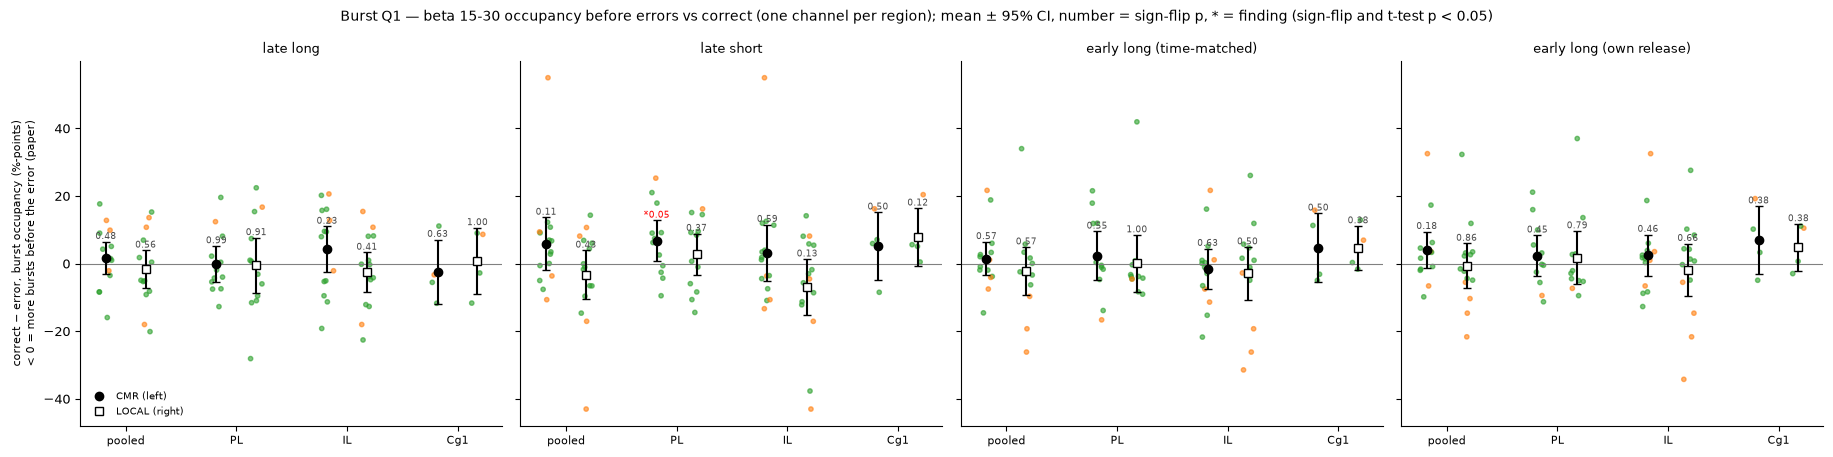

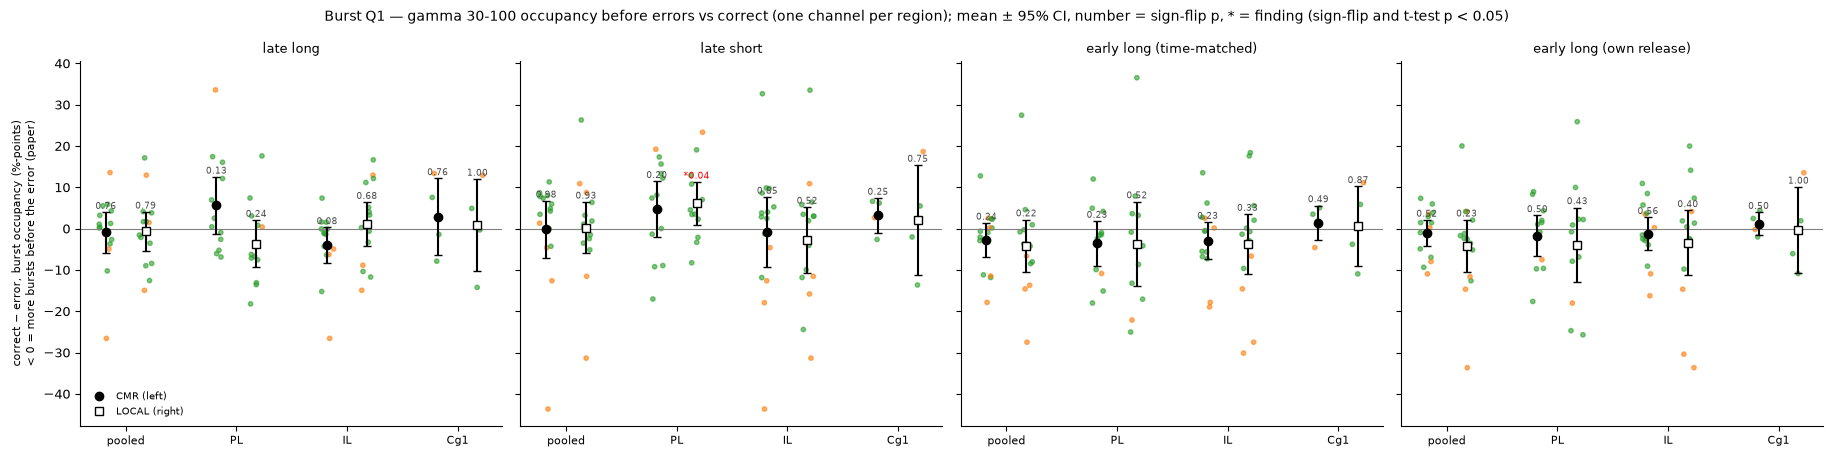

In [20]:
# %%
# ── 6b. BURST Q1, ALL FINISHED SESSIONS ──
importlib.reload(fn)
from scipy.stats import ttest_1samp
FAR_UM = 300
RAT_COL = {"134": "#1f77b4", "135": "#ff7f0e", "136": "#2ca02c"}
files = [s for s in final["session"] if os.path.exists(os.path.join(BURST_DIR, s + ".npz"))]
print(f"burst files: {len(files)}")
TABS, FAR = {b: {"late": [], "early": []} for b in BURST_BANDS_R}, set()
for s in files:
    z = np.load(os.path.join(BURST_DIR, s + ".npz")); T = pd.read_csv(os.path.join(BURST_DIR, s + "_trials.csv"))
    FAR |= {(s, k.split("|")[0], k.split("|")[1]) for k in z.files if k.endswith("|distance_um") and z[k][0] > FAR_UM}
    for band in BURST_BANDS_R:
        L, E = fn.burst_trial_tables(z, T, band, min_rt=MIN_RT)
        TABS[band]["late"].append(L.assign(session=s, rat=RAT[s])); TABS[band]["early"].append(E.assign(session=s, rat=RAT[s]))
TABS = {b: {w: pd.concat(v, ignore_index=True) for w, v in d.items()} for b, d in TABS.items()}

def without_far(df, ref):
    """drop region rows of far channels, rebuild 'mPFC pooled' from the remaining regions of each trial"""
    reg = df[(df["ref"] == ref) & (df["group"] != "mPFC pooled")]
    reg = reg[[(s, ref, g) not in FAR for s, g in zip(reg["session"], reg["group"])]]
    pooled = reg.groupby(["ref", "typ", "session", "rat", "trial", "cond"], as_index=False)["occ"].mean().assign(group="mPFC pooled")
    return pd.concat([reg, pooled], ignore_index=True)

def stats(v):
    v = np.asarray(v, float); v = v[np.isfinite(v)]
    mn, p_sf, n = fn.sign_flip_p(v)
    return mn, p_sf, (ttest_1samp(v, 0).pvalue if n >= 3 else np.nan), n, int((v > 0).sum())

rows, vals = [], []
for band in BURST_BANDS_R:
    for name, which, typ, a, b in TESTS6:
        df = TABS[band][which]
        for g in GROUPS6:
            for ref in ("CMR", "LOCAL"):
                V = fn.burst_session_values(df, ref, g, typ, a, b, MIN_TR)
                if len(V) < 2:
                    continue
                vals.append(V.assign(band=band, test=name, group=g, ref=ref))
                mn, p_sf, p_t, n, npos = stats(V["value"])
                loo = max(fn.sign_flip_p(V["value"].drop(i).values, n_perm=2000)[1] for i in V.index) if n >= 4 else np.nan
                Vf = fn.burst_session_values(without_far(df, ref), ref, g, typ, a, b, MIN_TR)
                mn_f, p_far, _, n_far, _ = stats(Vf["value"]) if len(Vf) >= 2 else (np.nan, np.nan, np.nan, 0, 0)
                per_rat = {f"rat {r}": f"{gg['value'].mean():+.1f} ({(gg['value'] > 0).sum()}/{len(gg)})" for r, gg in V.groupby("rat")}
                rows.append(dict(band=band, test=name, group=g, ref=ref, n=n, mean=mn, p_signflip=p_sf, p_ttest=p_t, n_pos=npos,
                                 finding=bool((p_sf < 0.05) and (p_t < 0.05)), loo_max_p=loo,
                                 n_without_far=n_far, mean_without_far=mn_f, p_without_far=p_far, **per_rat))
S6 = pd.DataFrame(rows); V6 = pd.concat(vals, ignore_index=True) if vals else pd.DataFrame()
S6.to_csv(os.path.join(TABLES, "burst_q1_stats.csv"), index=False); V6.to_csv(os.path.join(TABLES, "burst_q1_session_values.csv"), index=False)

if len(S6):
    S6["main"] = S6.apply(lambda x: f"{x['mean']:+.2f}  sf p={x.p_signflip:.3f}  t p={x.p_ttest:.3f}  ({x.n_pos}/{x.n})"
                          + ("  ◀ FINDING" if x.finding else ""), axis=1)
    S6["checks"] = S6.apply(lambda x: f"LOO {x.loo_max_p:.2f} | no-far p={x.p_without_far:.3f} (n={x.n_without_far})", axis=1)
    print("Q1: value = correct − error, burst occupancy %-points; + = more bursts in CORRECT; paper direction = NEGATIVE")
    for (band, name), d in S6.groupby(["band", "test"], sort=False):
        print(f"\n===== {band} | {name} =====")
        print(d.pivot_table(index="group", columns="ref", values="main", aggfunc="first").reindex(GROUPS6).to_string())
        print(d.pivot_table(index="group", columns="ref", values="checks", aggfunc="first").reindex(GROUPS6).to_string())
        rc = [c for c in S6.columns if c.startswith("rat ")]
        print(d.set_index(["group", "ref"])[rc].to_string())

    for band in BURST_BANDS_R:
        fig, axes = plt.subplots(1, len(TESTS6), figsize=(4.6 * len(TESTS6), 4.6), squeeze=False, sharey=True)
        for j, (name, *_) in enumerate(TESTS6):
            ax = axes[0, j]
            for gi, g in enumerate(GROUPS6):
                for ri, ref in enumerate(("CMR", "LOCAL")):
                    x0 = gi + (ri - 0.5) * 0.36
                    V = V6[(V6["band"] == band) & (V6["test"] == name) & (V6["group"] == g) & (V6["ref"] == ref)]
                    if not len(V):
                        continue
                    jit = np.random.default_rng(gi * 10 + ri).uniform(-0.06, 0.06, len(V))
                    ax.scatter(x0 + jit, V["value"], c=[RAT_COL[r] for r in V["rat"]], s=10, alpha=0.6, zorder=2)
                    m, se = V["value"].mean(), V["value"].std(ddof=1) / np.sqrt(len(V))
                    ax.errorbar(x0, m, yerr=1.96 * se, fmt="s" if ref == "LOCAL" else "o", color="k",
                                mfc="w" if ref == "LOCAL" else "k", ms=6, capsize=3, zorder=3)
                    st = S6[(S6["band"] == band) & (S6["test"] == name) & (S6["group"] == g) & (S6["ref"] == ref)].iloc[0]
                    ax.text(x0, m + 1.96 * se + 0.8, ("*" if st.finding else "") + f"{st.p_signflip:.2f}",
                            ha="center", fontsize=6.5, color="r" if st.finding else "0.3")
            ax.axhline(0, color="0.5", lw=0.8)
            ax.set_xticks(range(len(GROUPS6))); ax.set_xticklabels([g.replace("mPFC pooled", "pooled") for g in GROUPS6], fontsize=8)
            ax.set_title(name, fontsize=9)
            if j == 0:
                ax.set_ylabel("correct − error, burst occupancy (%-points)\n< 0 = more bursts before the error (paper)", fontsize=8)
            for sp in ("top", "right"): ax.spines[sp].set_visible(False)
        axes[0, 0].plot([], [], "o", color="k", label="CMR (left)"); axes[0, 0].plot([], [], "s", color="k", mfc="w", label="LOCAL (right)")
        axes[0, 0].legend(fontsize=7, frameon=False, loc="lower left")
        fig.suptitle(f"Burst Q1 — {band} occupancy before errors vs correct (one channel per region); mean ± 95% CI, "
                     "number = sign-flip p, * = finding (sign-flip and t-test p < 0.05)", fontsize=10)
        fig.tight_layout()
        fig.savefig(os.path.join(FIGS, f"burst_q1_{band.split()[0]}.png"), dpi=150, facecolor="white", bbox_inches="tight")
        plt.show()

<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

## 7. Burst Q2 (paper Fig. S6): is the success rate lower with more bursts before the tone?
Correct + late trials, burst occupancy in the pre-tone window (long −0.6..0 s, short −0.3..0 s); success = correct.
(a) Paper: occupancy bins quiet = 0, low <= 25 %, medium <= 50 %, high > 50 % of the window. Per session and bin (>= 3 trials):
success rate as PCM = % change from the session's mean success rate. One-way ANOVA across bins (sessions = observations) + Tukey HSD.
(b) Ours: per session Spearman rho (trial occupancy vs success 0/1); sign-flip across sessions + leave-one-session-out.
rho < 0 = more bursts -> less success (paper direction). FINDING = ANOVA p < 0.05 AND sign-flip p < 0.05. Raw p.
Sessions need >= MIN_TR correct and >= MIN_TR late trials of that type (MIN_TR = 1, new filter).
Earlier result (beta, 2026-10-22): no ANOVA effect for beta; theta PL short ANOVA p = 0.013.

<div>

<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

### 7a. Burst Q2 on the test session
Trials per occupancy bin and success rate per bin (pooled, CMR) for beta and gamma, long and short.
One session cannot be tested; this only checks the bins.

<div>

In [21]:
# %%
# ── 7a. BURST Q2, TEST SESSION (bins only) ──
OBINS = ["quiet", "low", "medium", "high"]
def obin(o):
    return np.select([o <= 0, o <= 0.25, o <= 0.5], [0, 1, 2], default=3)

z = np.load(os.path.join(BURST_DIR, TEST + ".npz")); T = pd.read_csv(os.path.join(BURST_DIR, TEST + "_trials.csv"))
for band in BURST_BANDS_R:
    L, _ = fn.burst_trial_tables(z, T, band, min_rt=MIN_RT)
    g = L[(L["ref"] == "CMR") & (L["group"] == "mPFC pooled")].copy()
    g["bin"] = pd.Categorical(np.array(OBINS)[obin(g["occ"].values)], OBINS)
    g["success"] = g["cond"].eq("correct").astype(float)
    print(f"\n{band} (CMR, pooled): trials and success rate per bin")
    print(g.groupby(["typ", "bin"], observed=False)["success"].agg(trials="size", success_rate="mean").round(2).to_string())


beta 15-30 (CMR, pooled): trials and success rate per bin
              trials  success_rate
typ   bin                         
long  quiet        0           NaN
      low         23          0.87
      medium      28          1.00
      high         1          1.00
short quiet        6          0.33
      low         39          0.74
      medium      25          0.68
      high         0           NaN

gamma 30-100 (CMR, pooled): trials and success rate per bin
              trials  success_rate
typ   bin                         
long  quiet        0           NaN
      low          0           NaN
      medium      25          0.96
      high        27          0.93
short quiet        0           NaN
      low          4          0.75
      medium      30          0.67
      high        36          0.69


<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

### 7b. Burst Q2 across all finished sessions (beta and gamma)
PCM per bin, ANOVA + Tukey, per-session rho + sign-flip, per rat; figure per band in the paper's Fig. S6 style
(PCM per bin, mean ± SEM over sessions; rows = reference, columns = group; long and short).
Saved: tables\burst_q2_pcm_bins.csv, burst_q2_rho_sessions.csv, burst_q2_stats.csv, figures\07_results\burst_q2_<band>.png.

<div>

Q2: PCM = success rate per bin, % change from the session mean (n sessions); paper: PCM falls from quiet to high
    rho = Spearman(occupancy, success) per session; < 0 = paper direction; finding = ANOVA p < 0.05 and sign-flip p < 0.05

===== beta 15-30 | long trials =====
  ref       group PCM quiet   PCM low PCM medium   PCM high          ANOVA                Tukey                           rho_cell flag
  CMR mPFC pooled  -4.8 (1) -2.9 (13)  -0.3 (13)   -0.1 (8) F=0.13 p=0.882                      +0.026 p=0.651 (6/14 neg) LOO 0.98     
  CMR          PL +10.0 (6) +1.6 (11)  -4.2 (12)  +1.8 (10) F=3.24 p=0.034 quiet-medium p=0.019 -0.018 p=0.770 (7/12 neg) LOO 1.00     
  CMR          IL  -5.0 (8) -1.1 (14)  -1.2 (13)  +5.0 (11) F=0.98 p=0.412                      +0.058 p=0.358 (6/14 neg) LOO 0.61     
  CMR         Cg1  +8.2 (3)  +0.8 (4)   -1.5 (4)   -0.4 (3) F=0.37 p=0.779                       -0.043 p=0.506 (3/4 neg) LOO 1.00     
LOCAL mPFC pooled +20.1 (2) -1.9 (13)  +1.2 (1

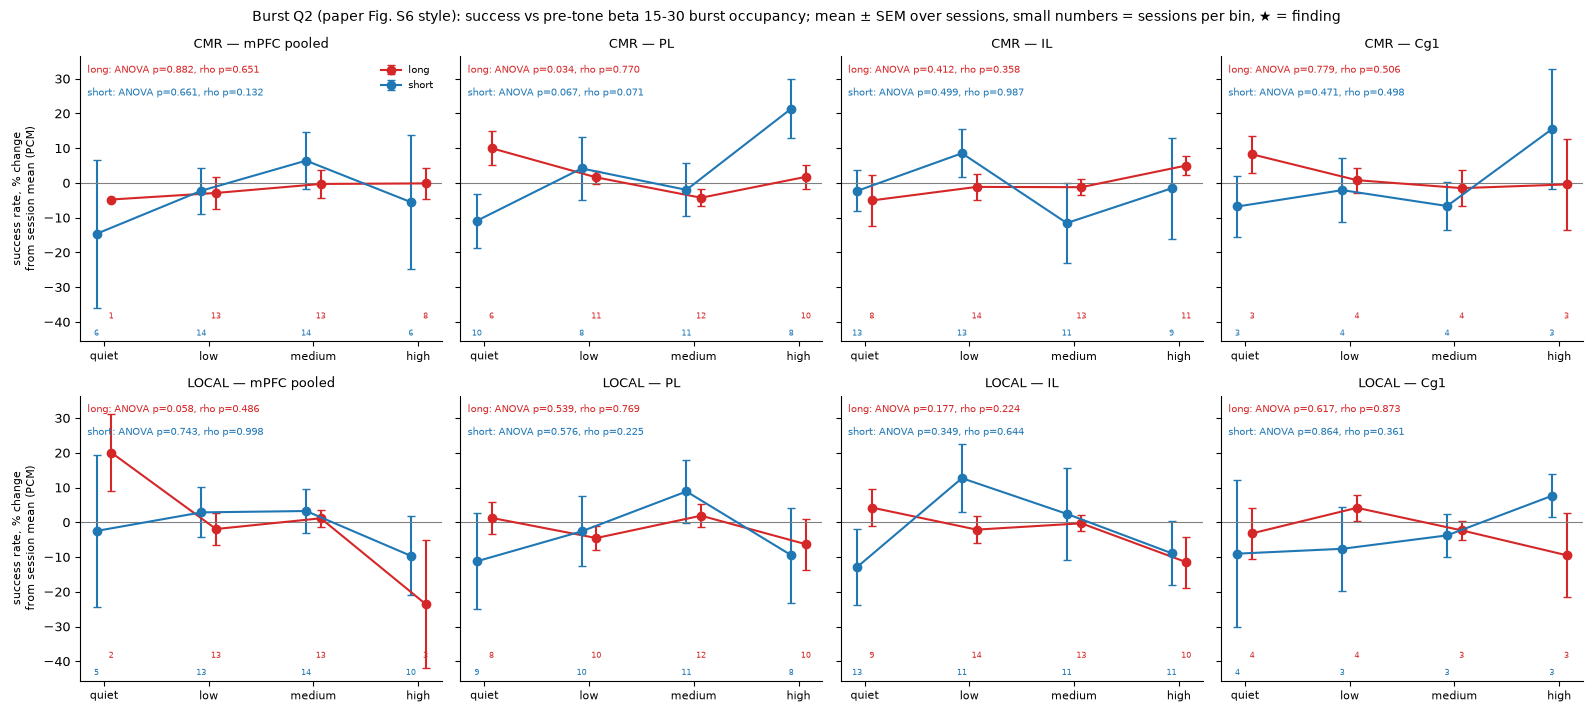

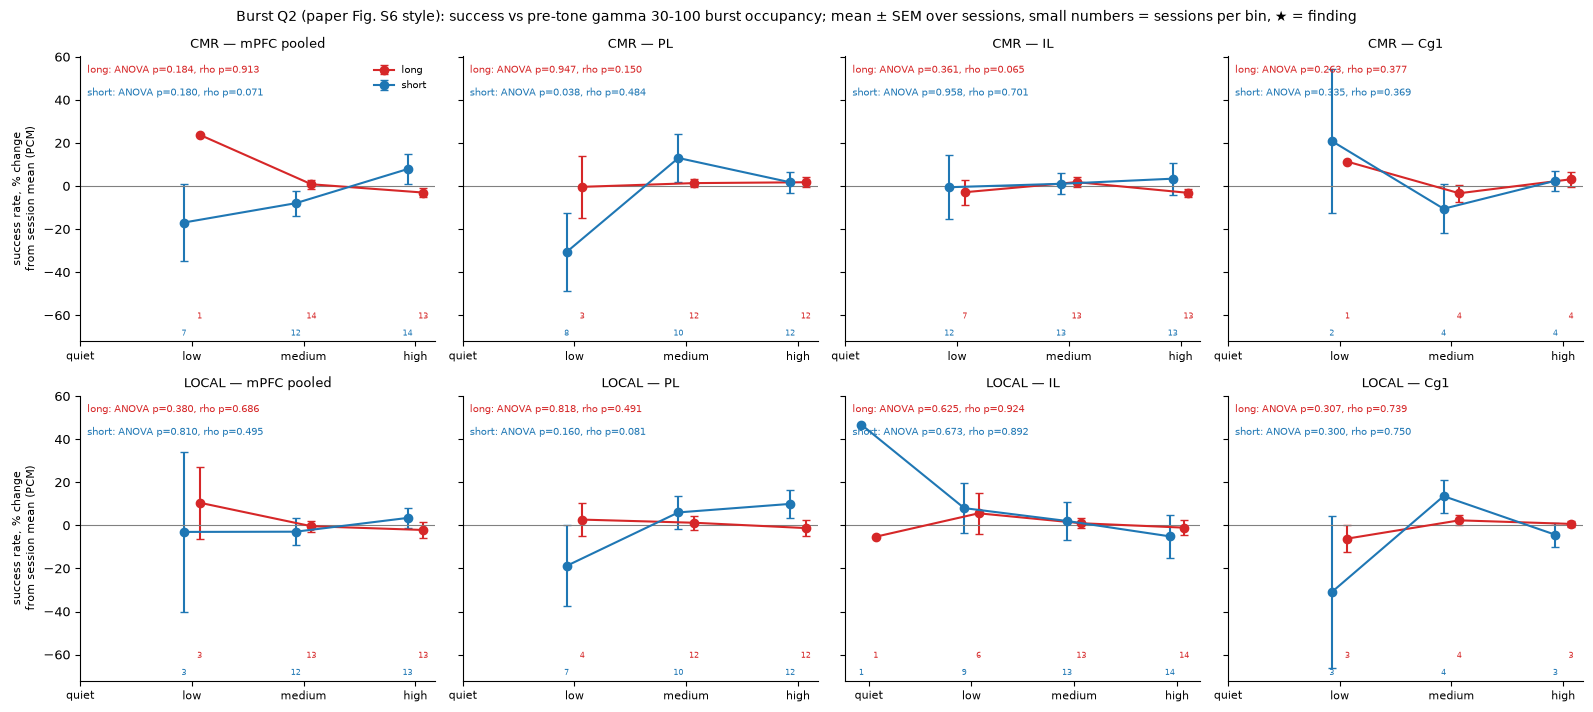

In [22]:
# %%
# ── 7b. BURST Q2, ALL FINISHED SESSIONS (needs 6b: TABS, GROUPS6, BURST_BANDS_R, MIN_TR) ──
from scipy.stats import f_oneway, tukey_hsd, spearmanr
MIN_BIN = 3
prows, rrows, arows = [], [], []
for band in BURST_BANDS_R:
    L = TABS[band]["late"]
    n = L.groupby(["ref", "typ", "session"])["cond"].agg(n_c=lambda x: (x == "correct").sum(), n_l=lambda x: (x == "late").sum())
    ok_s = n[(n["n_c"] >= MIN_TR) & (n["n_l"] >= MIN_TR)].reset_index()[["ref", "typ", "session"]]
    T7 = L.merge(ok_s, on=["ref", "typ", "session"])
    T7 = T7.assign(obin=obin(T7["occ"].values), success=T7["cond"].eq("correct").astype(float))
    for (ref, grp, typ), g in T7.groupby(["ref", "group", "typ"], sort=False):
        sm = g.groupby("session")["success"].mean()
        ps = g.groupby(["session", "rat", "obin"])["success"].agg(["mean", "size"]).reset_index()
        ps = ps[ps["size"] >= MIN_BIN]
        ps["pcm"] = 100 * (ps["mean"] - ps["session"].map(sm)) / ps["session"].map(sm)
        prows.append(ps.assign(band=band, ref=ref, group=grp, typ=typ))
        grp_pcm = [ps.loc[ps["obin"] == b, "pcm"].dropna().values for b in range(4)]
        okb = [b for b in range(4) if len(grp_pcm[b]) >= 3]
        F, pA, tk = np.nan, np.nan, ""
        if len(okb) >= 2:
            F, pA = f_oneway(*[grp_pcm[b] for b in okb])
            if pA < 0.05:
                res = tukey_hsd(*[grp_pcm[b] for b in okb])
                tk = "; ".join(f"{OBINS[okb[i]]}-{OBINS[okb[j]]} p={res.pvalue[i, j]:.3f}"
                               for i in range(len(okb)) for j in range(i + 1, len(okb)) if res.pvalue[i, j] < 0.05)
        rho = [dict(session=s, rat=rat, rho=spearmanr(gs["occ"], gs["success"]).correlation)
               for (s, rat), gs in g.groupby(["session", "rat"]) if gs["occ"].nunique() > 2 and gs["success"].nunique() > 1]
        R = pd.DataFrame(rho, columns=["session", "rat", "rho"]).dropna(); rrows.append(R.assign(band=band, ref=ref, group=grp, typ=typ))
        mn, p, nn = fn.sign_flip_p(R["rho"].values)
        loo = max(fn.sign_flip_p(R["rho"].drop(i).values, n_perm=2000)[1] for i in R.index) if nn >= 4 else np.nan
        arows.append(dict(band=band, ref=ref, group=grp, typ=typ,
                          **{f"PCM {OBINS[b]}": (f"{np.mean(grp_pcm[b]):+.1f} ({len(grp_pcm[b])})" if len(grp_pcm[b]) else "—") for b in range(4)},
                          ANOVA=f"F={F:.2f} p={pA:.3f}" if np.isfinite(F) else "—", Tukey=tk, p_anova=pA,
                          rho_mean=mn, p_rho=p, rho_cell=f"{mn:+.3f} p={p:.3f} ({int((R['rho'] < 0).sum())}/{nn} neg) LOO {loo:.2f}",
                          finding=bool(np.isfinite(pA) and pA < 0.05 and p < 0.05),
                          **{f"rat {r}": f"{x['rho'].mean():+.3f} ({(x['rho'] < 0).sum()}/{len(x)} neg)" for r, x in R.groupby("rat")}))
P7 = pd.concat(prows, ignore_index=True) if prows else pd.DataFrame()
R7 = pd.concat(rrows, ignore_index=True) if rrows else pd.DataFrame()
A7 = pd.DataFrame(arows)
P7.to_csv(os.path.join(TABLES, "burst_q2_pcm_bins.csv"), index=False)
R7.to_csv(os.path.join(TABLES, "burst_q2_rho_sessions.csv"), index=False)
A7.to_csv(os.path.join(TABLES, "burst_q2_stats.csv"), index=False)

print("Q2: PCM = success rate per bin, % change from the session mean (n sessions); paper: PCM falls from quiet to high")
print("    rho = Spearman(occupancy, success) per session; < 0 = paper direction; finding = ANOVA p < 0.05 and sign-flip p < 0.05")
for band in BURST_BANDS_R:
    for typ in ("long", "short"):
        d = A7[(A7["band"] == band) & (A7["typ"] == typ)].copy()
        if d.empty:
            continue
        d["group"] = pd.Categorical(d["group"], GROUPS6); d = d.sort_values(["ref", "group"])
        d["flag"] = np.where(d["finding"], "◀ FINDING", "")
        print(f"\n===== {band} | {typ} trials =====")
        print(d[["ref", "group"] + [f"PCM {b}" for b in OBINS] + ["ANOVA", "Tukey", "rho_cell", "flag"]].to_string(index=False))
        rc = [c for c in d.columns if c.startswith("rat ")]
        print(d[["ref", "group"] + rc].to_string(index=False))

for band in BURST_BANDS_R:
    if P7.empty or A7[A7["band"] == band].empty:
        continue
    fig, axes = plt.subplots(2, len(GROUPS6), figsize=(4 * len(GROUPS6), 7.2), squeeze=False, sharey=True)
    for i, ref in enumerate(("CMR", "LOCAL")):
        for j, grp in enumerate(GROUPS6):
            ax = axes[i, j]; title = f"{ref} — {grp}"
            for typ, col, dx in (("long", "#d62728", 0.07), ("short", "#1f77b4", -0.07)):
                ps = P7[(P7["band"] == band) & (P7["ref"] == ref) & (P7["group"] == grp) & (P7["typ"] == typ)]
                a = A7[(A7["band"] == band) & (A7["ref"] == ref) & (A7["group"] == grp) & (A7["typ"] == typ)]
                if ps.empty or a.empty:
                    continue
                a = a.iloc[0]
                st = ps.groupby("obin")["pcm"].agg(["mean", "sem", "size"]).reindex(range(4))
                ax.errorbar(np.arange(4) + dx, st["mean"], yerr=st["sem"], marker="o", color=col, capsize=3, label=typ)
                ax.text(0.02, 0.97 if typ == "long" else 0.89, f"{typ}: ANOVA p={a.p_anova:.3f}, rho p={a.p_rho:.3f}"
                        + ("  ★ FINDING" if a.finding else ""), transform=ax.transAxes, fontsize=7, va="top",
                        color="k" if a.finding else col, fontweight="bold" if a.finding else "normal",
                        bbox=dict(boxstyle="round,pad=0.2", fc="#ffe066", ec="none") if a.finding else None)
                if a.finding:
                    title += f"   ★ {typ}"
                for b in range(4):
                    if np.isfinite(st["size"].iat[b]):
                        ax.text(b + dx, 0.08 if typ == "long" else 0.02, f"{int(st['size'].iat[b])}", fontsize=6, color=col,
                                ha="center", transform=ax.get_xaxis_transform())
            ax.axhline(0, color="0.5", lw=0.8); ax.set_xticks(range(4)); ax.set_xticklabels(OBINS, fontsize=8)
            ax.set_title(title, fontsize=9)
            if j == 0: ax.set_ylabel("success rate, % change\nfrom session mean (PCM)", fontsize=8)
            for sp in ("top", "right"): ax.spines[sp].set_visible(False)
    axes[0, 0].legend(fontsize=7, frameon=False, loc="upper right")
    fig.suptitle(f"Burst Q2 (paper Fig. S6 style): success vs pre-tone {band} burst occupancy; mean ± SEM over sessions, "
                 "small numbers = sessions per bin, ★ = finding", fontsize=10)
    fig.tight_layout()
    fig.savefig(os.path.join(FIGS, f"burst_q2_{band.split()[0]}.png"), dpi=150, facecolor="white", bbox_inches="tight")
    plt.show()

In [23]:
# %%
# ── CHECK: the late long trials of one session, and late long counts in all sessions ──
SES_CHK = TEST
TRk = pd.read_csv(os.path.join(TABLES, "trials_filtered.csv"), dtype={"rat": str}, low_memory=False)
Kk = TRk[TRk["keep"]]

# 1. the late long trials of this session
t = Kk[(Kk["session"] == SES_CHK) & (Kk["label"] == "late") & (Kk["type"] == "long")]
print(f"{SES_CHK}: {len(t)} late long trials")
print(t[["trial_index", "long_prob", "hold_duration", "rt_s", "press_from_ttl"]].round(3).to_string(index=False))

# 2. their pre-tone beta burst occupancy (−0.6..0 s before the tone), per region, CMR, vs the correct long trials
z = np.load(os.path.join(BURST_DIR, SES_CHK + ".npz")); T = pd.read_csv(os.path.join(BURST_DIR, SES_CHK + "_trials.csv"))
L, _ = fn.burst_trial_tables(z, T, "beta 15-30", min_rt=None)
d = L[(L["ref"] == "CMR") & (L["typ"] == "long")]
print("\nbeta occupancy before the tone (fraction of the 0.6 s window), CMR:")
print(d.pivot_table(index="group", columns="cond", values="occ", aggfunc=["mean", "count"]).round(3).to_string())
print("\nthe 3 late trials one by one:")
print(d[d["cond"] == "late"].pivot_table(index="trial", columns="group", values="occ").round(3).to_string())

# 3. late long trials per session (all final sessions)
n = Kk[(Kk["label"] == "late") & (Kk["type"] == "long")].groupby("session").size().reindex(final["session"], fill_value=0)
print("\nlate long trials per session: 0 →", int((n == 0).sum()), "| 1–4 →", int(((n >= 1) & (n <= 4)).sum()),
      "| 5–9 →", int(((n >= 5) & (n <= 9)).sum()), "| ≥ 10 →", int((n >= 10).sum()), "sessions")
print(n.groupby(final.set_index("session")["rat"]).describe()[["count", "min", "50%", "max"]].to_string())

20260529_r0000136_wt_1318: 3 late long trials
 trial_index  long_prob  hold_duration  rt_s  press_from_ttl
          14        0.5           2.23  1.18            True
          96        0.5           1.59  0.54            True
         162        0.5           3.93  2.88            True

beta occupancy before the tone (fraction of the 0.6 s window), CMR:
               mean          count     
cond        correct   late correct late
group                                  
Cg1           0.287  0.176      49    3
IL            0.252  0.050      49    3
PL            0.287  0.329      49    3
mPFC pooled   0.275  0.185      49    3

the 3 late trials one by one:
group    Cg1    IL     PL  mPFC pooled
trial                                 
12     0.255  0.15  0.323        0.243
80     0.132  0.00  0.442        0.191
137    0.142  0.00  0.223        0.122

late long trials per session: 0 → 9 | 1–4 → 18 | 5–9 → 17 | ≥ 10 → 16 sessions
     count  min  50%   max
rat                       
1